# ThreatLens AI — Lexical Phishing-URL Detection with Exact, Per-URL Explanations

**A reproducible study: from raw public data to a deployed, explainable classifier**

School of Computing & Informatics, Albukhary International University · ThreatLens AI research team

---

### Abstract

Phishing attacks reach victims through deceptive links, yet many detectors depend on fetching the page or querying a reputation service. Those approaches are slow, can leak what the user is checking, and know nothing about newly registered domains. We study how well phishing can be detected from the **URL string alone**, under a deployment constraint: every prediction must come with an **exact, additive per-URL explanation**. We use a public, balanced corpus of 11,203 de-duplicated URLs (Hannousse & Yahiouche, 2021) and 33 lexical features computed by the production feature extractor. Eight learners and two baselines are compared under **domain-grouped cross-validation**, so that no registrable domain is shared between training and evaluation data. The selected model, a tuned Extra Trees ensemble with exact tree-path explanations, reaches **PR-AUC 0.928** (95% cluster-bootstrap CI 0.901–0.949), accuracy 0.857 and precision 0.894 at recall 0.771 on a held-out set of unseen domains. Requiring exact explanations costs 0.009 PR-AUC relative to histogram gradient boosting, a difference that is not statistically significant (corrected resampled *t*-test, *p* = 0.09). Random splits and the dataset's official split place roughly half of the test URLs on domains already seen in training. They inflate PR-AUC by 0.037–0.040 for the tree ensemble but only by about 0.02 for logistic regression, so flexible models benefit most from domain memorisation. On data from other sources, the model flags 79% of fresh OpenPhish URLs and about 3% of the 1,000 most-linked legitimate domains, mostly URL shorteners. Character-composition features carry most of the signal, HTTPS is a weak indicator, and performance plateaus with more data from the same source. The model is deployed in the ThreatLens AI web application, with its explanations verified to reproduce every prediction exactly.

---

### Research questions

| | Question |
|---|---|
| **RQ1** | How accurately can phishing URLs be detected from the URL string alone (no page fetch, no reputation lookup)? |
| **RQ2** | Which model family performs best, and what does requiring *exact* per-URL explanations cost in accuracy? |
| **RQ3** | How much do random train/test splits overestimate performance compared with domain-disjoint splits? |
| **RQ4** | Does the model generalise to phishing and legitimate URLs from sources it never saw? |
| **RQ5** | Which lexical signals drive the predictions, and where does the model fail? |

### How to read this notebook

The notebook runs top to bottom with no manual steps. Every figure is saved to `ml/reports/figures/` and every table to `ml/reports/tables/`, so both can go straight into the paper. Section 18 deploys the selected model into the backend and validates it with the production loader.

**Safety.** Phishing URLs are never visited. Any phishing URL shown is *defanged* (`hxxp://example[.]com`) so it cannot be clicked.

## 1. Environment and reproducibility

All randomness is controlled by a single seed. Versions are recorded because the exported model is a scikit-learn pickle, which only loads reliably under the scikit-learn version it was trained with (pinned in `ml/requirements.txt` and `backend/requirements.txt`).

**Google Colab.** The next cell clones the repository and installs the pinned environment. If Colab asks you to restart the session after installation, restart it and choose *Run all* again.

In [1]:
# 1.1  Optional Google Colab bootstrap (no-op when running locally)
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    repo_dir = Path("/content/ThreatLens-AI")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/AbdouSalamSisawo/ThreatLens-AI.git", str(repo_dir)], check=True)
    os.chdir(repo_dir / "ml" / "notebooks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "../requirements.txt"], check=True)
    print("Colab environment ready. If numpy/scikit-learn were upgraded, restart the session and Run all.")
else:
    print("Running locally")

Running locally


In [2]:
# 1.2  Imports and global settings
import hashlib
import ipaddress
import json
import platform
import time
import urllib.request
import warnings
from datetime import datetime, timezone

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.stats import loguniform
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss, confusion_matrix,
                             f1_score, matthews_corrcoef, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedGroupKFold, StratifiedKFold,
                                     cross_validate, learning_curve)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
N_JOBS = -1
N_FOLDS = 5
MAX_URL_LEN = 2048          # the API rejects longer URLs, so the corpus does too
DECISION_THRESHOLD = 0.5    # binary decision boundary used by the backend
np.random.seed(SEED)
warnings.filterwarnings("ignore", message="X does not have valid feature names")
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

In [3]:
# 1.3  Paths and the backend's shared feature extractor
def find_repo_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "backend" / "app" / "services" / "feature_extractor.py").exists():
            return p
    raise RuntimeError("Run this notebook from inside the ThreatLens-AI repository.")

REPO = find_repo_root(Path.cwd().resolve())
ML_DIR, BACKEND_DIR = REPO / "ml", REPO / "backend"
RAW_DIR, PROCESSED_DIR = ML_DIR / "data" / "raw", ML_DIR / "data" / "processed"
FIG_DIR, TAB_DIR = ML_DIR / "reports" / "figures", ML_DIR / "reports" / "tables"
ARTIFACTS_DIR = BACKEND_DIR / "artifacts"
for d in (RAW_DIR, PROCESSED_DIR, FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)

# The SAME module the API uses at inference time: train/serve skew is impossible by construction.
sys.path.insert(0, str(BACKEND_DIR))
from app.services.feature_extractor import (FEATURE_DESCRIPTIONS, FEATURE_NAMES, FEATURE_SCHEMA_VERSION,  # noqa: E402
                                            URLValidationError, extract_features, normalise_url_for_dedup,
                                            parse_url)
from app.services.explanation_service import compute_model_evidence  # noqa: E402

FEATURE_NAMES = list(FEATURE_NAMES)
env = pd.DataFrame({
    "component": ["python", "platform", "scikit-learn", "numpy", "pandas", "scipy", "matplotlib", "joblib",
                  "feature schema", "n features", "random seed", "run started (UTC)"],
    "value": [platform.python_version(), platform.platform(), sklearn.__version__, np.__version__, pd.__version__,
              scipy.__version__, matplotlib.__version__, joblib.__version__, FEATURE_SCHEMA_VERSION,
              len(FEATURE_NAMES), SEED, datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M")],
})
env.to_csv(TAB_DIR / "environment.csv", index=False)
env

,component,value
0,python,3.12.6
1,platform,Windows-11-10.0.26300-SP0
2,scikit-learn,1.6.1
3,numpy,2.5.5
4,pandas,2.3.3
5,scipy,1.18.1
6,matplotlib,3.10.8
7,joblib,1.6.0
8,feature schema,1.1.0
9,n features,33


In [4]:
# 1.4  Figure style, colours and helpers
SURFACE, INK, INK_2, GRID, NEUTRAL = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#8a8984"
CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834"}                  # legitimate = blue, phishing = orange
CLASS_NAMES = {0: "legitimate", 1: "phishing"}
# Validated categorical set (CVD-safe across all pairs); line style is a second encoding.
MODEL_STYLE = {
    "logistic_regression":    dict(color="#6250d6", ls="-",  label="Logistic Regression"),
    "hist_gradient_boosting": dict(color="#eda100", ls="--", label="Hist. Gradient Boosting"),
    "random_forest":          dict(color="#1baf7a", ls="-.", label="Random Forest"),
    "extra_trees":            dict(color="#008300", ls=":",  label="Extra Trees"),
}
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_orange", ["#2a78d6", "#f0efec", "#eb6834"])
SEQUENTIAL = LinearSegmentedColormap.from_list("blue_seq", ["#f0f5fc", "#86b6ef", "#2a78d6", "#104281"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 9.5, "axes.titlesize": 10.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": INK_2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK_2,
    "ytick.color": INK_2, "legend.frameon": False, "lines.linewidth": 2,
})

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

def save_table(df, name, index=False):
    df.to_csv(TAB_DIR / f"{name}.csv", index=index)
    return df

def defang(url: str) -> str:
    return url.replace("https://", "hxxps://").replace("http://", "hxxp://").replace(".", "[.]")

def short(s: str, n: int = 70) -> str:
    return s if len(s) <= n else s[: n - 1] + "…"

def binary_metrics(y_true, proba, threshold=DECISION_THRESHOLD) -> dict:
    y_true, proba = np.asarray(y_true), np.asarray(proba)
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "f1": f1_score(y_true, pred, zero_division=0),
        "mcc": matthews_corrcoef(y_true, pred),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
        "brier": brier_score_loss(y_true, proba),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

def features_of(urls) -> pd.DataFrame:
    return pd.DataFrame([extract_features(u) for u in urls], columns=FEATURE_NAMES).astype(float)

print("Figures ->", FIG_DIR.relative_to(REPO), "| Tables ->", TAB_DIR.relative_to(REPO))

Figures -> ml\reports\figures | Tables -> ml\reports\tables


## 2. Data acquisition and provenance

Every file is fetched from its **original public source**. A file already present in `ml/data/raw/` is reused, but it is always checked against the SHA-256 of the snapshot analysed in this study. A mismatch is reported, not hidden: the OpenPhish feed and the Majestic list change daily, so a fresh download is a new snapshot and its date must be recorded.

| Source | Role in the study |
|---|---|
| `pirocheto/phishing-url` (Hugging Face; Hannousse & Yahiouche) | The only **labelled** data: training, model selection and testing |
| OpenPhish community feed | **Evaluation only**: recall on fresh phishing URLs from a different source |
| Majestic Million | **Evaluation only**: false-positive rate on the web's most-linked legitimate domains |

Licences and the full attribution are in `ml/data/README.md`.

In [5]:
SOURCES = [
    dict(file="train.parquet", source="Hugging Face: pirocheto/phishing-url (data/train.parquet)",
         url="https://huggingface.co/datasets/pirocheto/phishing-url/resolve/main/data/train.parquet",
         licence="CC-BY-4.0", role="labelled corpus", snapshot="2026-10-29",
         sha256="79a776a41e7f5c8a51d24ec6802284887fbdee296c5e09e8d881fc6c4852cc43"),
    dict(file="test.parquet", source="Hugging Face: pirocheto/phishing-url (data/test.parquet)",
         url="https://huggingface.co/datasets/pirocheto/phishing-url/resolve/main/data/test.parquet",
         licence="CC-BY-4.0", role="labelled corpus", snapshot="2026-10-29",
         sha256="8131f6e48b58136dac0222b419104d19d7d47938483d0a458403113750222a07"),
    dict(file="openphish_feed.txt", source="OpenPhish community feed",
         url="https://openphish.com/feed.txt",
         licence="OpenPhish community terms (non-commercial, attribution)", role="out-of-source phishing probe",
         snapshot="2026-10-29",
         sha256="17c6d6a6d7b2d4761595702614501b3bd91fe95a632435eec7a7a1dd94f22956"),
    dict(file="majestic_million.csv", source="Majestic Million",
         url="https://downloads.majestic.com/majestic_million.csv",
         licence="Free download with attribution", role="out-of-source legitimate probe", snapshot="2026-10-29",
         sha256="4ade3e01ea61e3792dce4b254dd871efe267e79e377289dfcea42b24b8471711"),
]

def sha256_of(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def acquire(src: dict) -> dict:
    path = RAW_DIR / src["file"]
    action = "reused local copy"
    if not path.exists():
        req = urllib.request.Request(src["url"], headers={"User-Agent": "ThreatLens-AI-research/1.0"})
        with urllib.request.urlopen(req, timeout=300) as resp:
            path.write_bytes(resp.read())
        action = f"downloaded {datetime.now(timezone.utc):%Y-%m-%d}"
    digest = sha256_of(path)
    return {"file": src["file"], "source": src["source"], "url": src["url"], "licence": src["licence"],
            "role": src["role"], "action": action, "size_kb": round(path.stat().st_size / 1024, 1),
            "sha256": digest, "matches_study_snapshot": digest == src["sha256"],
            "snapshot_date": src["snapshot"] if digest == src["sha256"] else "NEW SNAPSHOT - record date"}

provenance = pd.DataFrame([acquire(s) for s in SOURCES])
save_table(provenance, "t01_data_provenance")
for row in provenance.itertuples():
    if not row.matches_study_snapshot:
        print(f"WARNING: {row.file} differs from the study snapshot - results describe a new snapshot.")
provenance[["file", "role", "licence", "action", "size_kb", "matches_study_snapshot", "snapshot_date"]]

,file,role,licence,action,size_kb,matches_study_snapshot,snapshot_date
0,train.parquet,labelled corpus,CC-BY-4.0,reused local copy,770.5000,True,2026-10-29
1,test.parquet,labelled corpus,CC-BY-4.0,reused local copy,420.6000,True,2026-10-29
2,openphish_feed.txt,out-of-source phishing probe,"OpenPhish community terms (non-commercial, attribution)",reused local copy,15.3000,True,2026-10-29
3,majestic_million.csv,out-of-source legitimate probe,Free download with attribution,reused local copy,1599.2000,True,2026-10-29


## 3. Data cleaning

The Hugging Face release contains 87 pre-computed features per URL. **All of them are discarded.** Only the raw `url` and its `status` label are kept, and every feature is recomputed by the backend's extractor. A model trained on the dataset's own features could never be served, because the live API only sees a URL.

Cleaning steps, in order:

1. Combine the official train and test files. We define our own split in §6, because the official split shares domains (measured below).
2. Normalise labels (`phishing` → 1, `legitimate` → 0) and drop anything unmappable.
3. Drop URLs longer than 2,048 characters (the API rejects them) and URLs the production parser cannot parse.
4. Drop URLs whose canonical form carries **both** labels (label noise).
5. De-duplicate on the canonical form (case, `www.`, default port and trailing slash normalised).

In [6]:
frames = []
for name in ("train.parquet", "test.parquet"):
    part = pd.read_parquet(RAW_DIR / name, columns=["url", "status"])
    part["hf_split"] = name.split(".")[0]
    frames.append(part)
raw = pd.concat(frames, ignore_index=True)
flow = [("Loaded from source (official train + test)", len(raw))]

raw["label"] = raw["status"].astype(str).str.strip().str.lower().map({"phishing": 1, "legitimate": 0})
data = raw.dropna(subset=["label"]).copy()
data["label"] = data["label"].astype(int)
data["url"] = data["url"].astype(str).str.strip()
data = data[data["url"].str.len() > 0]
flow.append(("Valid label and non-empty URL", len(data)))

data = data[data["url"].str.len() <= MAX_URL_LEN]
flow.append((f"Length <= {MAX_URL_LEN} characters", len(data)))

def parses(u: str) -> bool:
    try:
        parse_url(u)
        return True
    except URLValidationError:
        return False

data = data[data["url"].map(parses)]
flow.append(("Parsable by the production URL parser", len(data)))

data["canonical"] = data["url"].map(normalise_url_for_dedup)
labels_per_url = data.groupby("canonical")["label"].nunique()
conflicting = set(labels_per_url[labels_per_url > 1].index)
data = data[~data["canonical"].isin(conflicting)]
flow.append(("No label conflict", len(data)))

splits_per_url = data.groupby("canonical")["hf_split"].nunique()
n_cross_split_duplicates = int((splits_per_url > 1).sum())
data = data.drop_duplicates("canonical", keep="first").reset_index(drop=True)
flow.append(("Unique canonical URL", len(data)))

def domain_group(url: str) -> str:
    # Grouping key for leakage control: registrable domain, or the literal IP for IP-hosted URLs.
    p = parse_url(url)
    host = (p.hostname or "").lower().strip("[]")
    try:
        ipaddress.ip_address(host)
        return host
    except ValueError:
        return p.registrable_domain.lower()

data["domain"] = data["url"].map(domain_group)
data[["url", "label", "hf_split", "domain"]].to_parquet(PROCESSED_DIR / "phishing_urls_clean.parquet", index=False)

flow_df = pd.DataFrame(flow, columns=["step", "records"])
flow_df["removed"] = (-flow_df["records"].diff()).fillna(0).astype(int)
save_table(flow_df, "t02_cleaning_flow")
display(flow_df)
print(f"Retained {len(data):,} of {len(raw):,} records ({len(data) / len(raw):.1%}).")
print(f"Canonical URLs present in BOTH official splits before de-duplication: {n_cross_split_duplicates}")

,step,records,removed
0,Loaded from source (official train + test),11430,0
1,Valid label and non-empty URL,11430,0
2,Length <= 2048 characters,11430,0
3,Parsable by the production URL parser,11430,0
4,No label conflict,11430,0
5,Unique canonical URL,11203,227


Retained 11,203 of 11,430 records (98.0%).
Canonical URLs present in BOTH official splits before de-duplication: 106


In [7]:
class_table = (data.groupby("label").size().rename("urls").to_frame()
               .assign(share=lambda t: t["urls"] / t["urls"].sum())
               .rename(index=CLASS_NAMES))
class_table["unique_domains"] = data.groupby("label")["domain"].nunique().rename(index=CLASS_NAMES)
save_table(class_table.reset_index(names="class"), "t03_class_balance")
class_table

,urls,share,unique_domains
label,,,
legitimate,5715,0.5101,3903
phishing,5488,0.4899,2599


## 4. Exploratory data analysis

We look at the raw URLs before any modelling, to understand what separates the classes and where shortcuts or leakage could hide.

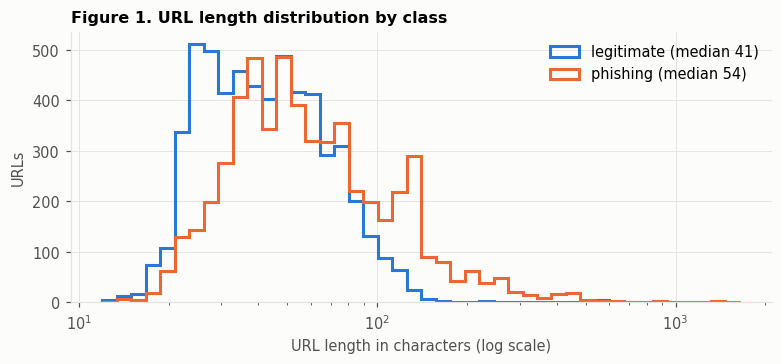

Mann-Whitney U on URL length: U=20,753,240, p=4.84e-193


In [8]:
lengths = data["url"].str.len()
fig, ax = plt.subplots(figsize=(7.2, 3.4))
bins = np.logspace(np.log10(max(lengths.min(), 8)), np.log10(lengths.max()), 45)
for c in (0, 1):
    ax.hist(lengths[data["label"] == c], bins=bins, histtype="step", lw=2, color=CLASS_COLORS[c],
            label=f"{CLASS_NAMES[c]} (median {int(lengths[data['label'] == c].median())})")
ax.set_xscale("log")
ax.set_xlabel("URL length in characters (log scale)")
ax.set_ylabel("URLs")
ax.set_title("Figure 1. URL length distribution by class")
ax.legend(loc="upper right")
save_fig(fig, "fig01_url_length_by_class")

u, p = stats.mannwhitneyu(lengths[data["label"] == 1], lengths[data["label"] == 0])
print(f"Mann-Whitney U on URL length: U={u:,.0f}, p={p:.2e}")

,legitimate,phishing
scheme,,
http,0.5550,0.6662
https,0.4450,0.3338


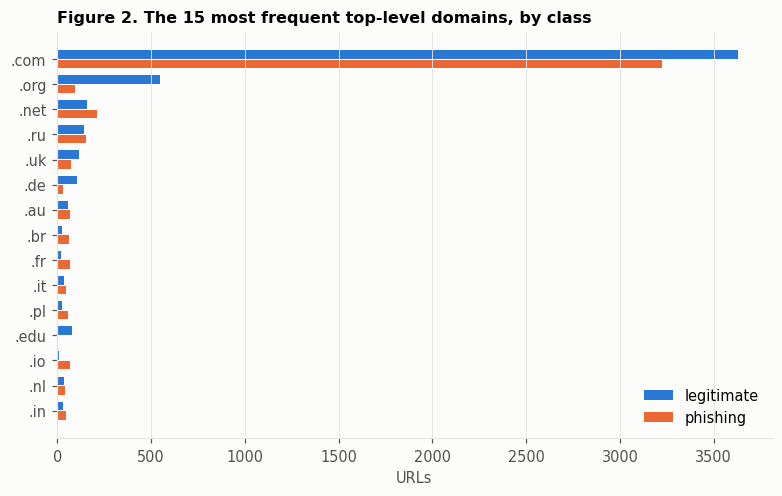

In [9]:
parsed = data["url"].map(parse_url)
data["scheme"] = parsed.map(lambda p: p.scheme)
data["tld"] = parsed.map(lambda p: (p.hostname or "").rsplit(".", 1)[-1].lower())

scheme_table = (pd.crosstab(data["scheme"], data["label"].map(CLASS_NAMES), normalize="columns")
                .rename_axis(None, axis=1))
save_table(scheme_table.reset_index(names="scheme"), "t04_scheme_by_class")
display(scheme_table)

top_tlds = data["tld"].value_counts().head(15).index
tld_counts = pd.crosstab(data["tld"], data["label"]).reindex(top_tlds)
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ypos = np.arange(len(top_tlds))
h = 0.38
for i, c in enumerate((0, 1)):
    ax.barh(ypos + (i - 0.5) * h, tld_counts[c], height=h - 0.04, color=CLASS_COLORS[c], label=CLASS_NAMES[c])
ax.set_yticks(ypos, [f".{t}" for t in top_tlds])
ax.invert_yaxis()
ax.set_xlabel("URLs")
ax.set_title("Figure 2. The 15 most frequent top-level domains, by class")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "fig02_top_tlds_by_class")

,class,urls,unique_domains,urls_per_domain_mean,largest_domain_urls,share_urls_in_domains_with_5plus
0,legitimate,5715,3903,1.4643,177,0.2602
1,phishing,5488,2599,2.1116,307,0.4193


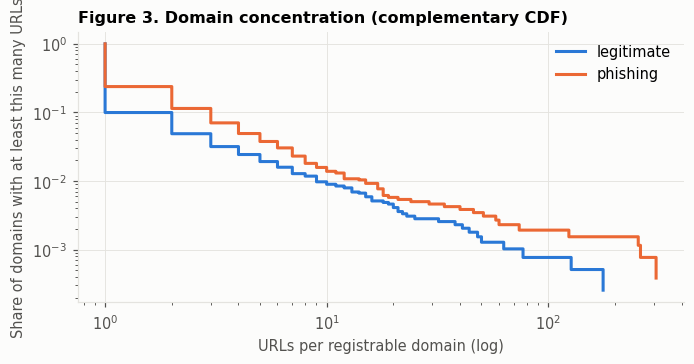

Official split: 48.6% of official-test URLs come from a domain that also appears in official-train (1,767 of 3,639). This is the leakage §6 removes.


In [10]:
dom_sizes = data.groupby(["label", "domain"]).size().rename("urls").reset_index()
conc = []
for c in (0, 1):
    s = dom_sizes.loc[dom_sizes["label"] == c, "urls"]
    conc.append({"class": CLASS_NAMES[c], "urls": int(s.sum()), "unique_domains": len(s),
                 "urls_per_domain_mean": s.mean(), "largest_domain_urls": int(s.max()),
                 "share_urls_in_domains_with_5plus": s[s >= 5].sum() / s.sum()})
concentration = save_table(pd.DataFrame(conc), "t05_domain_concentration")
display(concentration)

fig, ax = plt.subplots(figsize=(6.4, 3.4))
for c in (0, 1):
    s = np.sort(dom_sizes.loc[dom_sizes["label"] == c, "urls"].to_numpy())
    ccdf = 1 - np.arange(len(s)) / len(s)
    ax.step(s, ccdf, where="post", color=CLASS_COLORS[c], label=CLASS_NAMES[c])
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("URLs per registrable domain (log)")
ax.set_ylabel("Share of domains with at least this many URLs")
ax.set_title("Figure 3. Domain concentration (complementary CDF)")
ax.legend()
save_fig(fig, "fig03_domain_concentration")

hf_train_domains = set(data.loc[data["hf_split"] == "train", "domain"])
hf_test = data[data["hf_split"] == "test"]
shared = hf_test["domain"].isin(hf_train_domains)
print(f"Official split: {shared.mean():.1%} of official-test URLs come from a domain that also appears in "
      f"official-train ({int(shared.sum()):,} of {len(hf_test):,}). This is the leakage §6 removes.")

## 5. Feature extraction and univariate analysis

All 33 features come from `backend/app/services/feature_extractor.py` (schema shown in §1). They are purely lexical: no DNS lookup, no WHOIS, no page fetch. That makes the classifier safe to run on hostile input, because it never contacts the URL.

For the analysis and the ablation study (§15) the features are grouped into five families.

In [11]:
FEATURE_GROUPS = {
    "length": ["url_length", "hostname_length", "path_length", "query_length", "has_long_hostname"],
    "character composition": ["nb_dots_url", "nb_dots_hostname", "nb_hyphens_url", "nb_hyphens_hostname",
                              "nb_underscores_url", "nb_digits_url", "nb_digits_hostname", "ratio_digits_url",
                              "ratio_digits_hostname", "nb_pct_encoded", "nb_ampersand", "nb_at_symbol",
                              "hostname_entropy"],
    "host structure": ["nb_subdomain_labels", "has_ip", "has_non_standard_port", "has_credentials_pattern",
                       "has_punycode", "nb_hex_labels_hostname"],
    "scheme, path and query": ["is_https", "nb_query_params", "nb_double_slash_path", "path_depth"],
    "curated lexicons": ["is_shortener_domain", "has_suspicious_tld", "has_executable_extension",
                         "nb_suspicious_tokens", "has_brand_token_outside_domain"],
}
GROUP_OF = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
assert sorted(GROUP_OF) == sorted(FEATURE_NAMES), "every feature must belong to exactly one group"

t0 = time.perf_counter()
X = features_of(data["url"])
extract_seconds = time.perf_counter() - t0
y = data["label"].to_numpy()
groups = data["domain"].to_numpy()
urls = data["url"].to_numpy()
print(f"Extracted {X.shape[1]} features for {X.shape[0]:,} URLs in {extract_seconds:.1f}s "
      f"({extract_seconds / len(X) * 1e3:.3f} ms per URL)")

taxonomy = pd.DataFrame({"feature": FEATURE_NAMES, "group": [GROUP_OF[f] for f in FEATURE_NAMES],
                         "description": [FEATURE_DESCRIPTIONS[f] for f in FEATURE_NAMES]})
save_table(taxonomy, "t06_feature_taxonomy")
taxonomy

Extracted 33 features for 11,203 URLs in 10.2s (0.908 ms per URL)


,feature,group,description
0,url_length,length,Total character length of the submitted URL.
1,hostname_length,length,Character length of the hostname.
2,path_length,length,Character length of the path component.
3,query_length,length,Character length of the query string.
4,nb_dots_url,character composition,Number of '.' characters in the full URL.
5,nb_dots_hostname,character composition,Number of '.' characters in the hostname.
6,nb_subdomain_labels,host structure,Estimated number of subdomain labels beyond registrable domain.
7,nb_hyphens_url,character composition,Number of '-' characters in the full URL.
8,nb_hyphens_hostname,character composition,Number of '-' characters in the hostname.
9,nb_underscores_url,character composition,Number of '_' characters in the full URL.


**Effect sizes.** For each feature we report Cliff's δ, a non-parametric effect size in [−1, 1]. A positive δ means larger values are more typical of phishing. We use the conventional thresholds |δ| ≥ 0.147 (small), ≥ 0.33 (medium) and ≥ 0.474 (large). *p*-values come from two-sided Mann–Whitney *U* tests, Bonferroni-corrected for 33 comparisons. Mutual information (MI) captures non-monotonic dependence as well.

In [12]:
binary_features = [f for f in FEATURE_NAMES if set(np.unique(X[f])) <= {0.0, 1.0}]
rows = []
for f in FEATURE_NAMES:
    a, b = X.loc[y == 1, f], X.loc[y == 0, f]
    if X[f].nunique() <= 1:
        delta, pval = 0.0, 1.0
    else:
        u_stat, pval = stats.mannwhitneyu(a, b, alternative="two-sided")
        delta = 2 * u_stat / (len(a) * len(b)) - 1
    rows.append({"feature": f, "group": GROUP_OF[f], "type": "binary" if f in binary_features else "numeric",
                 "mean_phishing": a.mean(), "mean_legitimate": b.mean(),
                 "nonzero_phishing": (a != 0).mean(), "nonzero_legitimate": (b != 0).mean(),
                 "cliffs_delta": delta, "p_value": pval})
univariate = pd.DataFrame(rows)
univariate["p_bonferroni"] = np.minimum(univariate["p_value"] * len(univariate), 1.0)
univariate["mutual_info"] = mutual_info_classif(X, y, discrete_features=[f in binary_features for f in FEATURE_NAMES],
                                                 random_state=SEED)
univariate["effect"] = pd.cut(univariate["cliffs_delta"].abs(), [-1, 0.147, 0.33, 0.474, 1.01],
                              labels=["negligible", "small", "medium", "large"])
univariate = univariate.sort_values("cliffs_delta", key=np.abs, ascending=False).reset_index(drop=True)
save_table(univariate, "t07_univariate_feature_analysis")
constant = [f for f in FEATURE_NAMES if X[f].nunique() <= 1]
print("Constant features in this corpus:", constant or "none")
univariate[["feature", "group", "mean_phishing", "mean_legitimate", "cliffs_delta", "effect", "p_bonferroni", "mutual_info"]]

Constant features in this corpus: ['has_credentials_pattern']


,feature,group,mean_phishing,mean_legitimate,cliffs_delta,effect,p_bonferroni,mutual_info
0,nb_digits_url,character composition,9.3872,1.5286,0.3901,medium,0.0000,0.1003
1,ratio_digits_url,character composition,0.0840,0.0213,0.3899,medium,0.0000,0.0956
2,url_length,length,74.9373,47.3815,0.3234,small,0.0000,0.0718
3,hostname_entropy,character composition,3.5428,3.3784,0.2686,small,0.0000,0.1172
4,path_depth,"scheme, path and query",2.2766,1.3675,0.2592,small,0.0000,0.0328
5,hostname_length,length,23.5758,18.5220,0.2130,small,0.0000,0.0566
6,query_length,length,17.2560,1.1878,0.2059,small,0.0000,0.0529
7,nb_query_params,"scheme, path and query",0.5219,0.0551,0.2046,small,0.0000,0.0552
8,nb_digits_hostname,character composition,1.2006,0.0668,0.1974,small,0.0000,0.0564
9,ratio_digits_hostname,character composition,0.0458,0.0041,0.1955,small,0.0000,0.0502


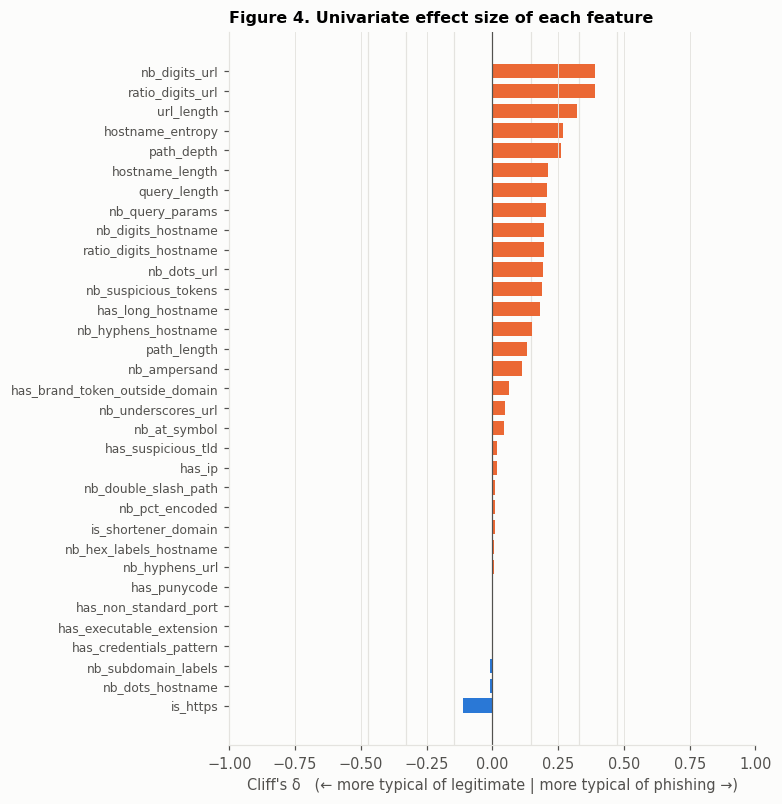

In [13]:
uv = univariate.sort_values("cliffs_delta")
fig, ax = plt.subplots(figsize=(7.2, 7.4))
colors = [CLASS_COLORS[1] if d > 0 else CLASS_COLORS[0] for d in uv["cliffs_delta"]]
ax.barh(uv["feature"], uv["cliffs_delta"], color=colors, height=0.72)
for t in (0.147, 0.33, 0.474):
    for s in (-1, 1):
        ax.axvline(s * t, color=GRID, lw=0.8, zorder=0)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_xlim(-1, 1)
ax.set_xlabel("Cliff's δ   (← more typical of legitimate | more typical of phishing →)")
ax.set_title("Figure 4. Univariate effect size of each feature")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
save_fig(fig, "fig04_feature_effect_sizes")

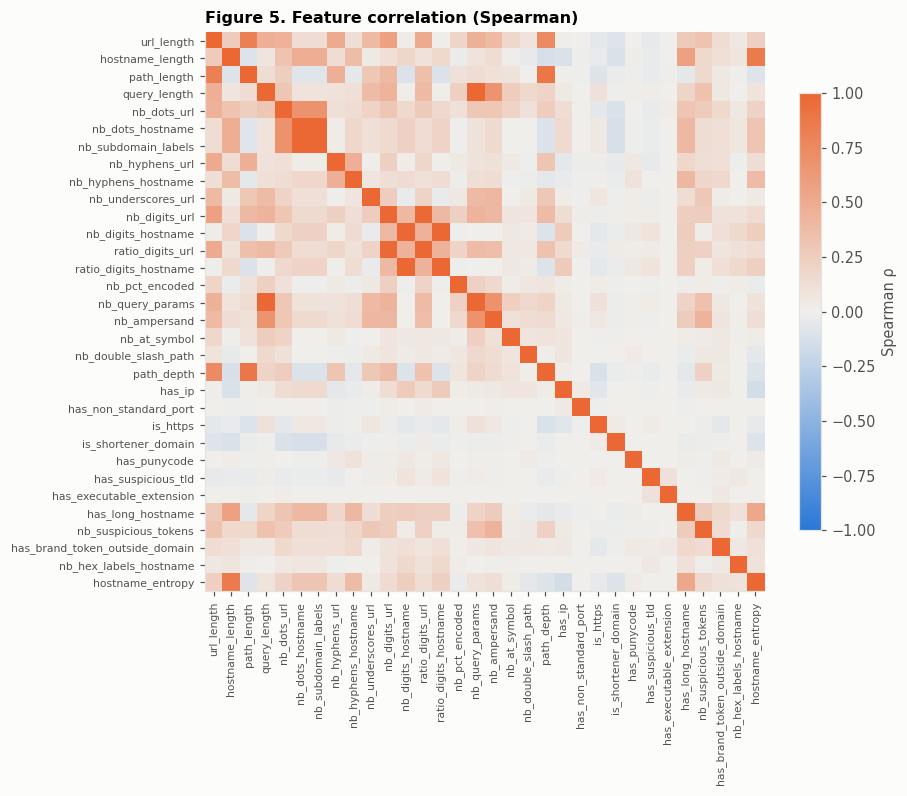

,feature_a,feature_b,spearman_rho
145,nb_dots_hostname,nb_subdomain_labels,1.0000
287,nb_digits_hostname,ratio_digits_hostname,0.9990
101,query_length,nb_query_params,0.9977
266,nb_digits_url,ratio_digits_url,0.9889
77,path_length,path_depth,0.8862
60,hostname_length,hostname_entropy,0.8577


In [14]:
varying = [f for f in FEATURE_NAMES if f not in constant]
rho = X[varying].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.4, 7.2))
im = ax.imshow(rho, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(varying)), varying, rotation=90, fontsize=7)
ax.set_yticks(range(len(varying)), varying, fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="Spearman ρ")
ax.set_title("Figure 5. Feature correlation (Spearman)")
save_fig(fig, "fig05_feature_correlation")

pairs = (rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack().rename("spearman_rho")
         .reset_index().rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
redundant = pairs[pairs["spearman_rho"].abs() >= 0.85].sort_values("spearman_rho", key=np.abs, ascending=False)
save_table(redundant, "t08_highly_correlated_pairs")
redundant

## 6. Experimental protocol

**Why domain-disjoint splits.** Many URLs share a registrable domain (§4). With a random split, the test set contains domains the model has already seen during training, and the model can score well by *memorising domains* instead of learning phishing patterns. A deployed scanner meets mostly unseen domains, so we evaluate on unseen domains:

* **Test set (20%).** Held out with `StratifiedGroupKFold` grouped by registrable domain (IP-hosted URLs grouped by IP). No domain appears in both development and test. **The test set is used once**, in §10.
* **Development set (80%).** All model comparison and tuning uses 5-fold `StratifiedGroupKFold` on this set. The *same* folds are reused for every model, which makes the comparisons paired.
* **Primary metric: PR-AUC** (average precision). It summarises precision and recall across every threshold and stays informative if the deployment base rate differs from this balanced corpus. ROC-AUC, F1, accuracy, MCC and Brier score are secondary.

In [15]:
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(outer.split(X, y, groups))
X_dev, X_test = X.iloc[dev_idx].reset_index(drop=True), X.iloc[test_idx].reset_index(drop=True)
y_dev, y_test = y[dev_idx], y[test_idx]
g_dev, g_test = groups[dev_idx], groups[test_idx]
urls_dev, urls_test = urls[dev_idx], urls[test_idx]
assert set(g_dev).isdisjoint(set(g_test)), "domain leakage between development and test"

CV = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
cv_splits = list(CV.split(X_dev, y_dev, g_dev))
for tr, va in cv_splits:
    assert set(g_dev[tr]).isdisjoint(set(g_dev[va]))

split_audit = pd.DataFrame([
    {"set": "development", "urls": len(y_dev), "phishing_share": y_dev.mean(), "unique_domains": len(set(g_dev))},
    {"set": "test (held out)", "urls": len(y_test), "phishing_share": y_test.mean(), "unique_domains": len(set(g_test))},
])
split_audit["domains_shared_with_other_set"] = 0
save_table(split_audit, "t09_split_audit")
display(split_audit)
fold_sizes = [len(va) for _, va in cv_splits]
print(f"{N_FOLDS} grouped CV folds on the development set; validation fold sizes: {fold_sizes}")

,set,urls,phishing_share,unique_domains,domains_shared_with_other_set
0,development,9093,0.5001,5168,0
1,test (held out),2110,0.4460,1288,0


5 grouped CV folds on the development set; validation fold sizes: [2004, 1478, 1512, 2132, 1967]


## 7. Baselines and model comparison

Two baselines anchor the comparison:

* **Majority class.** Always predicts the most frequent class (the chance level).
* **Red-flag rule.** A transparent rule of the kind a security analyst might write. It counts classic red flags (IP host, `@` in the URL, credentials in the URL, shortener, punycode, high-abuse TLD, executable download, brand outside the domain, urgency words, non-standard port, open-redirect `//`, hex host labels, no HTTPS) and flags a URL when the count reaches a threshold learned on the training folds by maximising balanced accuracy. (Maximising F1 instead degenerates on a balanced corpus: flagging *every* URL already scores F1 ≈ 0.66.)

Eight learners are then compared with library-default hyperparameters on the identical folds. The **explainable** column marks models for which the backend computes *exact* per-URL contributions that sum to the predicted probability: coefficient decomposition for logistic regression, tree-path decomposition for forests. Only these models can be deployed (§9).

In [16]:
RED_FLAGS = ["has_ip", "has_credentials_pattern", "nb_at_symbol", "is_shortener_domain", "has_punycode",
             "has_suspicious_tld", "has_executable_extension", "has_brand_token_outside_domain",
             "nb_suspicious_tokens", "has_non_standard_port", "nb_double_slash_path", "nb_hex_labels_hostname"]

class RedFlagBaseline(ClassifierMixin, BaseEstimator):
    # Rule baseline: count of red flags (+1 if not HTTPS); threshold maximises balanced accuracy on training data.
    def _score(self, X):
        X = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X, columns=FEATURE_NAMES)
        return (X[RED_FLAGS] > 0).sum(axis=1).to_numpy() + (X["is_https"] == 0).to_numpy().astype(int)

    def fit(self, X, y):
        s, y = self._score(X), np.asarray(y)
        candidates = range(0, int(s.max()) + 2)
        self.threshold_ = max(candidates, key=lambda t: balanced_accuracy_score(y, (s >= t).astype(int)))
        self.n_flags_ = len(RED_FLAGS) + 1
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        # Monotone in the flag count; crosses 0.5 exactly at the learned threshold.
        p = np.clip(0.5 + (self._score(X) - self.threshold_ + 0.5) / (2 * self.n_flags_ + 2), 0, 1)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

def scaled(clf):
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])

def bare(clf):
    return Pipeline([("clf", clf)])

CANDIDATES = {
    "majority_baseline":      (bare(DummyClassifier(strategy="most_frequent")), False),
    "red_flag_rule":          (RedFlagBaseline(), False),
    "logistic_regression":    (scaled(LogisticRegression(max_iter=5000, random_state=SEED)), True),
    "gaussian_naive_bayes":   (scaled(GaussianNB()), False),
    "k_nearest_neighbours":   (scaled(KNeighborsClassifier(n_neighbors=15)), False),
    "decision_tree":          (bare(DecisionTreeClassifier(random_state=SEED)), False),
    "mlp":                    (scaled(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, early_stopping=True,
                                                    random_state=SEED)), False),
    "random_forest":          (bare(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1)), True),
    "extra_trees":            (bare(ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=1)), True),
    "hist_gradient_boosting": (bare(HistGradientBoostingClassifier(random_state=SEED)), False),
}
SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "f1": "f1", "accuracy": "accuracy",
           "precision": "precision", "recall": "recall", "neg_brier": "neg_brier_score"}

fold_rows, t0 = [], time.perf_counter()
for name, (est, explainable) in CANDIDATES.items():
    res = cross_validate(est, X_dev, y_dev, cv=cv_splits, scoring=SCORING, n_jobs=N_JOBS)
    for k in range(N_FOLDS):
        fold_rows.append({"model": name, "fold": k, "explainable": explainable, "fit_seconds": res["fit_time"][k],
                          **{m: res[f"test_{m}"][k] for m in SCORING}})
default_folds = pd.DataFrame(fold_rows)
default_folds["brier"] = -default_folds.pop("neg_brier")
save_table(default_folds, "t10_default_models_cv_folds")
print(f"Default-model comparison finished in {time.perf_counter() - t0:.0f}s")

metric_cols = ["pr_auc", "roc_auc", "f1", "accuracy", "precision", "recall", "brier"]
default_summary = (default_folds.groupby(["model", "explainable"])[metric_cols + ["fit_seconds"]]
                   .agg(["mean", "std"]))
default_summary.columns = [f"{m}_{s}" for m, s in default_summary.columns]
default_summary = default_summary.reset_index().sort_values("pr_auc_mean", ascending=False)
save_table(default_summary, "t11_default_models_cv_summary")
default_summary[["model", "explainable", "pr_auc_mean", "pr_auc_std", "roc_auc_mean", "f1_mean", "accuracy_mean",
                 "brier_mean", "fit_seconds_mean"]]

Default-model comparison finished in 47s


,model,explainable,pr_auc_mean,pr_auc_std,roc_auc_mean,f1_mean,accuracy_mean,brier_mean,fit_seconds_mean
3,hist_gradient_boosting,False,0.9187,0.0229,0.9112,0.8204,0.8298,0.1193,1.9075
7,mlp,False,0.9134,0.0303,0.9108,0.8134,0.8257,0.1203,3.1271
8,random_forest,True,0.8989,0.0227,0.8967,0.8139,0.8200,0.1294,8.7292
5,logistic_regression,True,0.8897,0.0269,0.8846,0.7757,0.7943,0.1386,0.1484
4,k_nearest_neighbours,False,0.8811,0.0275,0.8824,0.7866,0.8012,0.1395,0.0354
1,extra_trees,True,0.8549,0.0325,0.8791,0.8100,0.8166,0.1386,8.4397
2,gaussian_naive_bayes,False,0.8490,0.0456,0.8420,0.4748,0.6623,0.3368,0.0607
0,decision_tree,False,0.6909,0.0500,0.7537,0.7458,0.7562,0.2436,0.1491
9,red_flag_rule,False,0.6466,0.0430,0.6707,0.4245,0.6149,0.2420,0.0410
6,majority_baseline,False,0.4919,0.0629,0.5000,0.2385,0.4481,0.5519,0.0143


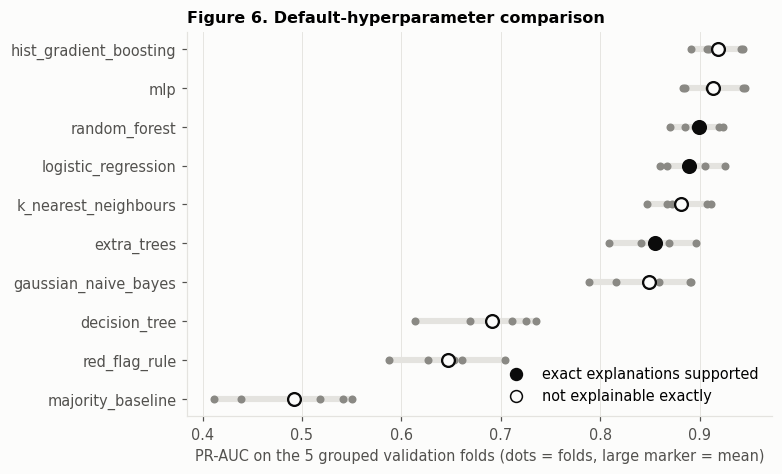

In [17]:
order = default_summary["model"].tolist()[::-1]
fig, ax = plt.subplots(figsize=(7.2, 4.4))
for i, name in enumerate(order):
    s = default_folds.loc[default_folds["model"] == name, "pr_auc"]
    expl = CANDIDATES[name][1]
    ax.plot([s.min(), s.max()], [i, i], color=GRID, lw=4, solid_capstyle="round", zorder=1)
    ax.scatter(s, np.full(len(s), i), s=18, color=NEUTRAL, zorder=2)
    ax.scatter(s.mean(), i, s=70, zorder=3, color=INK if expl else SURFACE, edgecolor=INK, linewidth=1.5)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("PR-AUC on the 5 grouped validation folds (dots = folds, large marker = mean)")
ax.set_title("Figure 6. Default-hyperparameter comparison")
ax.scatter([], [], s=60, color=INK, label="exact explanations supported")
ax.scatter([], [], s=60, color=SURFACE, edgecolor=INK, label="not explainable exactly")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "fig06_default_model_comparison")

## 8. Hyperparameter tuning

The four strongest model families are tuned by randomised search on the same grouped folds, optimising PR-AUC: logistic regression, random forest, extra trees, and histogram gradient boosting (the strongest family without exact explanations, kept as a reference). The search never touches the test set.

In [18]:
TREE_SPACE = {"clf__n_estimators": [200, 300, 500], "clf__max_depth": [None, 12, 20, 30],
              "clf__min_samples_leaf": [1, 2, 4, 8], "clf__max_features": ["sqrt", "log2", 0.3, 0.5],
              "clf__class_weight": [None, "balanced_subsample"]}
SEARCH = {
    "logistic_regression": (
        scaled(LogisticRegression(solver="liblinear", max_iter=5000, random_state=SEED)),
        {"clf__C": loguniform(1e-3, 1e3), "clf__penalty": ["l1", "l2"], "clf__class_weight": [None, "balanced"]}, 30),
    "random_forest": (bare(RandomForestClassifier(random_state=SEED, n_jobs=1)), TREE_SPACE, 30),
    "extra_trees": (bare(ExtraTreesClassifier(random_state=SEED, n_jobs=1)), TREE_SPACE, 30),
    "hist_gradient_boosting": (
        bare(HistGradientBoostingClassifier(random_state=SEED, early_stopping=False)),
        {"clf__learning_rate": loguniform(0.01, 0.3), "clf__max_iter": [100, 200, 400],
         "clf__max_leaf_nodes": [15, 31, 63], "clf__min_samples_leaf": [10, 20, 50],
         "clf__l2_regularization": loguniform(1e-4, 1.0), "clf__max_features": [0.5, 0.8, 1.0]}, 40),
}

tuned, tuning_rows = {}, []
for name, (est, space, n_iter) in SEARCH.items():
    t0 = time.perf_counter()
    search = RandomizedSearchCV(est, space, n_iter=n_iter, scoring="average_precision", cv=cv_splits,
                                n_jobs=N_JOBS, random_state=SEED, refit=False)
    search.fit(X_dev, y_dev)
    res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    save_table(res[["rank_test_score", "mean_test_score", "std_test_score", "params"]].head(10),
               f"t12_tuning_top10_{name}")
    best = search.best_params_
    tuned[name] = clone(est).set_params(**best)
    default_pr = default_summary.set_index("model").loc[name, "pr_auc_mean"]
    tuning_rows.append({"model": name, "configurations_tried": n_iter, "default_pr_auc": default_pr,
                        "tuned_pr_auc": search.best_score_, "gain": search.best_score_ - default_pr,
                        "search_seconds": time.perf_counter() - t0,
                        "best_params": json.dumps({k.replace("clf__", ""): v for k, v in best.items()}, default=str)})
tuning = save_table(pd.DataFrame(tuning_rows), "t13_tuning_summary")
tuning

,model,configurations_tried,default_pr_auc,tuned_pr_auc,gain,search_seconds,best_params
0,logistic_regression,30,0.8897,0.8898,0.0001,21.9605,"{""C"": 0.3905441275210791, ""class_weight"": null, ""penalty"": ""l1""}"
1,random_forest,30,0.8989,0.9109,0.0120,212.6604,"{""n_estimators"": 300, ""min_samples_leaf"": 4, ""max_features"": ""log2"", ""max_depth"": 30, ..."
2,extra_trees,30,0.8549,0.9114,0.0565,185.7345,"{""n_estimators"": 200, ""min_samples_leaf"": 2, ""max_features"": ""log2"", ""max_depth"": null..."
3,hist_gradient_boosting,40,0.9187,0.9198,0.0010,214.1845,"{""l2_regularization"": 0.034207303670092254, ""learning_rate"": 0.06185918211556436, ""max..."


## 9. Statistical comparison and model selection

A single 5-fold estimate is noisy, so each tuned model is re-evaluated with **3 × 5 repeated grouped CV** (15 paired folds). Neighbouring folds share training data, which makes the naive paired *t*-test overconfident. We therefore use the **Nadeau–Bengio corrected resampled *t*-test**, which inflates the variance by the factor (1/k + n_test/n_train).

**Selection rule.** This rule was fixed before tuning:

1. Only models with exact per-URL explanations in the backend are eligible (logistic regression, random forest, extra trees). Explainability is a product requirement, not a tie-breaker.
2. Among eligible models, choose the highest mean repeated-CV PR-AUC.
3. If logistic regression is within 0.01 PR-AUC of that leader **and** not significantly worse (corrected *p* ≥ 0.05), choose logistic regression, because it is the simplest model.
4. Report the *explainability cost*: the PR-AUC gap between the best model overall and the selected one.

In [19]:
REPEATS = 3
rep_splits = []
for r in range(REPEATS):
    rep_splits += list(StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED + 100 + r)
                       .split(X_dev, y_dev, g_dev))
n_tr = np.mean([len(tr) for tr, _ in rep_splits])
n_va = np.mean([len(va) for _, va in rep_splits])

REP_SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "f1": "f1", "accuracy": "accuracy",
               "precision": "precision", "recall": "recall"}
rep = {}
for name, est in tuned.items():
    res = cross_validate(est, X_dev, y_dev, cv=rep_splits, scoring=REP_SCORING, n_jobs=N_JOBS)
    rep[name] = {m: res[f"test_{m}"] for m in REP_SCORING}

def corrected_ttest(a, b):
    d = np.asarray(a) - np.asarray(b)
    k = len(d)
    se = np.sqrt((1 / k + n_va / n_tr) * d.var(ddof=1))
    t = d.mean() / se if se > 0 else np.inf
    return d.mean(), t, 2 * stats.t.sf(abs(t), df=k - 1)

rep_summary = pd.DataFrame([{"model": n, "explainable": n in {"logistic_regression", "random_forest", "extra_trees"},
                             **{f"{m}_mean": v.mean() for m, v in rep[n].items()},
                             "pr_auc_std": rep[n]["pr_auc"].std(ddof=1)} for n in rep]
                           ).sort_values("pr_auc_mean", ascending=False).reset_index(drop=True)
save_table(rep_summary, "t14_repeated_cv_tuned_models")
display(rep_summary)

leader_all = rep_summary.loc[0, "model"]
tests = []
for n in rep:
    if n != leader_all:
        d, t, p = corrected_ttest(rep[leader_all]["pr_auc"], rep[n]["pr_auc"])
        tests.append({"comparison": f"{leader_all} vs {n}", "mean_pr_auc_difference": d, "t": t, "p_corrected": p,
                      "significant_at_0.05": p < 0.05})
pairwise = save_table(pd.DataFrame(tests), "t15_corrected_ttests")
pairwise

,model,explainable,pr_auc_mean,roc_auc_mean,f1_mean,accuracy_mean,precision_mean,recall_mean,pr_auc_std
0,hist_gradient_boosting,False,0.9181,0.9113,0.8236,0.8316,0.8465,0.8027,0.0308
1,extra_trees,True,0.9094,0.9007,0.8014,0.8167,0.8546,0.7555,0.0349
2,random_forest,True,0.9079,0.9024,0.8068,0.8175,0.8368,0.7795,0.0337
3,logistic_regression,True,0.8830,0.8777,0.7677,0.7870,0.8222,0.7204,0.0412


,comparison,mean_pr_auc_difference,t,p_corrected,significant_at_0.05
0,hist_gradient_boosting vs logistic_regression,0.0351,3.6587,0.0026,True
1,hist_gradient_boosting vs random_forest,0.0102,2.0693,0.0575,False
2,hist_gradient_boosting vs extra_trees,0.0087,1.8106,0.0917,False


**Selected model: `extra_trees`.** extra_trees has the highest mean repeated grouped-CV PR-AUC among models with exact explanations (0.9094). Logistic regression is 0.0264 lower (corrected p = 0.00575), outside the simplicity tie-break, so extra_trees is kept.

**Explainability cost:** the best model overall is `hist_gradient_boosting` (0.9181); requiring exact explanations costs **0.0087 PR-AUC** (corrected p = 0.0917).

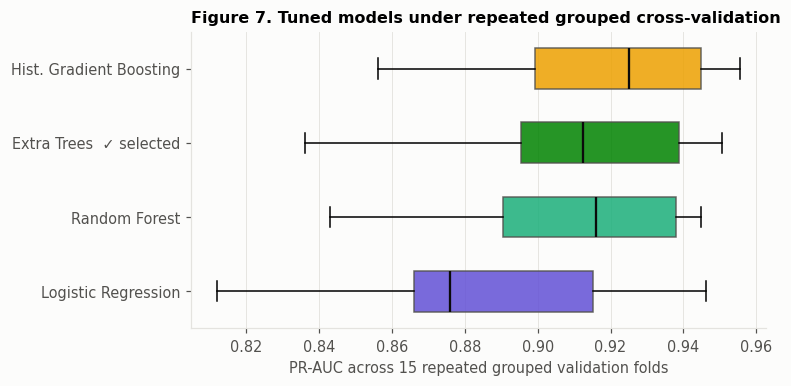

In [20]:
EXPLAINABLE = ["logistic_regression", "random_forest", "extra_trees"]
pr = {n: rep[n]["pr_auc"] for n in rep}
eligible = sorted(EXPLAINABLE, key=lambda n: pr[n].mean(), reverse=True)
leader = eligible[0]
selected = leader
reason = (f"{leader} has the highest mean repeated grouped-CV PR-AUC among models with exact explanations "
          f"({pr[leader].mean():.4f}).")
if leader != "logistic_regression":
    d, t, p = corrected_ttest(pr[leader], pr["logistic_regression"])
    if d <= 0.01 and p >= 0.05:
        selected = "logistic_regression"
        reason = (f"Logistic regression is within {d:.4f} PR-AUC of {leader} and not significantly worse "
                  f"(corrected p = {p:.3f}), so the simpler model is preferred.")
    else:
        reason += (f" Logistic regression is {d:.4f} lower (corrected p = {p:.3g}), outside the simplicity "
                   f"tie-break, so {leader} is kept.")
best_overall = max(pr, key=lambda n: pr[n].mean())
explainability_cost = pr[best_overall].mean() - pr[selected].mean()
d_cost, t_cost, p_cost = corrected_ttest(pr[best_overall], pr[selected]) if best_overall != selected else (0, 0, 1)

display(Markdown(f"**Selected model: `{selected}`.** {reason}\n\n"
                 f"**Explainability cost:** the best model overall is `{best_overall}` "
                 f"({pr[best_overall].mean():.4f}); requiring exact explanations costs "
                 f"**{explainability_cost:.4f} PR-AUC** (corrected p = {p_cost:.3g})."))

fig, ax = plt.subplots(figsize=(7.2, 3.6))
names = rep_summary["model"].tolist()
bp = ax.boxplot([pr[n] for n in names], vert=False, widths=0.55, patch_artist=True,
                medianprops=dict(color=INK, lw=1.5))
for patch, n in zip(bp["boxes"], names):
    patch.set(facecolor=MODEL_STYLE[n]["color"], alpha=0.85, edgecolor=INK_2)
ax.set_yticks(range(1, len(names) + 1), [MODEL_STYLE[n]["label"] + ("  ✓ selected" if n == selected else "")
                                          for n in names])
ax.invert_yaxis()
ax.set_xlabel("PR-AUC across 15 repeated grouped validation folds")
ax.set_title("Figure 7. Tuned models under repeated grouped cross-validation")
ax.grid(axis="y", visible=False)
save_fig(fig, "fig07_tuned_models_repeated_cv")

## 10. Held-out test evaluation

The selected configuration is refit on the full development set and evaluated **once** on the domain-disjoint test set. URLs from the same domain are correlated, so 95% confidence intervals come from a **cluster bootstrap that resamples domains** (2,000 replicates), not individual URLs.

In [21]:
final_dev = clone(tuned[selected])
t0 = time.perf_counter()
final_dev.fit(X_dev, y_dev)
fit_seconds_dev = time.perf_counter() - t0
p_test = final_dev.predict_proba(X_test)[:, 1]
test_m = binary_metrics(y_test, p_test)

rng = np.random.default_rng(SEED)
dom_index = pd.Series(np.arange(len(g_test))).groupby(g_test).apply(lambda s: s.to_numpy())
dom_keys = dom_index.index.to_numpy()
boot = []
for _ in range(2000):
    pick = rng.choice(dom_keys, size=len(dom_keys), replace=True)
    idx = np.concatenate(dom_index.loc[pick].to_numpy())
    if len(np.unique(y_test[idx])) == 2:
        boot.append(binary_metrics(y_test[idx], p_test[idx]))
boot = pd.DataFrame(boot)
ci_metrics = ["accuracy", "precision", "recall", "specificity", "f1", "mcc", "roc_auc", "pr_auc", "brier"]
test_table = pd.DataFrame({"metric": ci_metrics, "estimate": [test_m[m] for m in ci_metrics],
                           "ci95_low": [boot[m].quantile(0.025) for m in ci_metrics],
                           "ci95_high": [boot[m].quantile(0.975) for m in ci_metrics]})
save_table(test_table, "t16_test_metrics_with_ci")
display(Markdown(f"**{selected}** on {len(y_test):,} test URLs from {len(dom_keys):,} unseen domains "
                 f"(threshold {DECISION_THRESHOLD}); {len(boot)} valid bootstrap replicates."))
test_table

**extra_trees** on 2,110 test URLs from 1,288 unseen domains (threshold 0.5); 2000 valid bootstrap replicates.

,metric,estimate,ci95_low,ci95_high
0,accuracy,0.8569,0.8233,0.8871
1,precision,0.8940,0.8571,0.9234
2,recall,0.7705,0.7185,0.8162
3,specificity,0.9264,0.8972,0.9483
4,f1,0.8276,0.7885,0.8614
5,mcc,0.7121,0.6507,0.7646
6,roc_auc,0.9313,0.9099,0.9479
7,pr_auc,0.9276,0.9009,0.9487
8,brier,0.1115,0.0977,0.1261


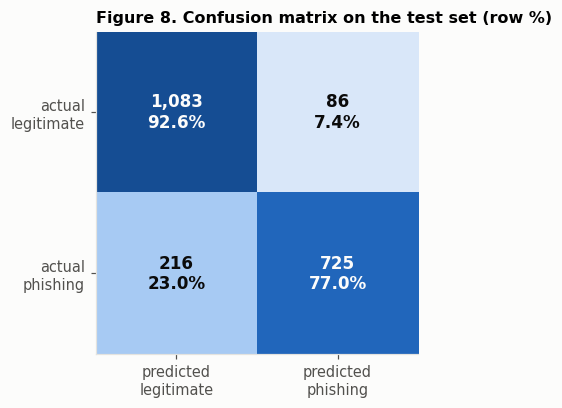

In [22]:
cm = np.array([[test_m["tn"], test_m["fp"]], [test_m["fn"], test_m["tp"]]])
fig, ax = plt.subplots(figsize=(4.4, 3.8))
ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap=SEQUENTIAL, vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        share = cm[i, j] / cm[i].sum()
        ax.text(j, i, f"{cm[i, j]:,}\n{share:.1%}", ha="center", va="center",
                color=SURFACE if share > 0.6 else INK, fontsize=11, fontweight="bold")
ax.set_xticks([0, 1], ["predicted\nlegitimate", "predicted\nphishing"])
ax.set_yticks([0, 1], ["actual\nlegitimate", "actual\nphishing"])
ax.grid(False)
ax.set_title("Figure 8. Confusion matrix on the test set (row %)")
save_fig(fig, "fig08_confusion_matrix")

,model,selected,pr_auc,roc_auc,f1,accuracy,precision,recall,mcc
3,hist_gradient_boosting,False,0.9373,0.9418,0.8536,0.8725,0.8750,0.8332,0.7415
1,random_forest,False,0.9309,0.9350,0.8448,0.8668,0.8793,0.8130,0.7302
2,extra_trees,True,0.9276,0.9313,0.8276,0.8569,0.8940,0.7705,0.7121
0,logistic_regression,False,0.9067,0.9081,0.7980,0.8313,0.8563,0.7471,0.6588
4,red_flag_rule,False,0.6021,0.6735,0.3354,0.6393,0.9412,0.2040,0.3259


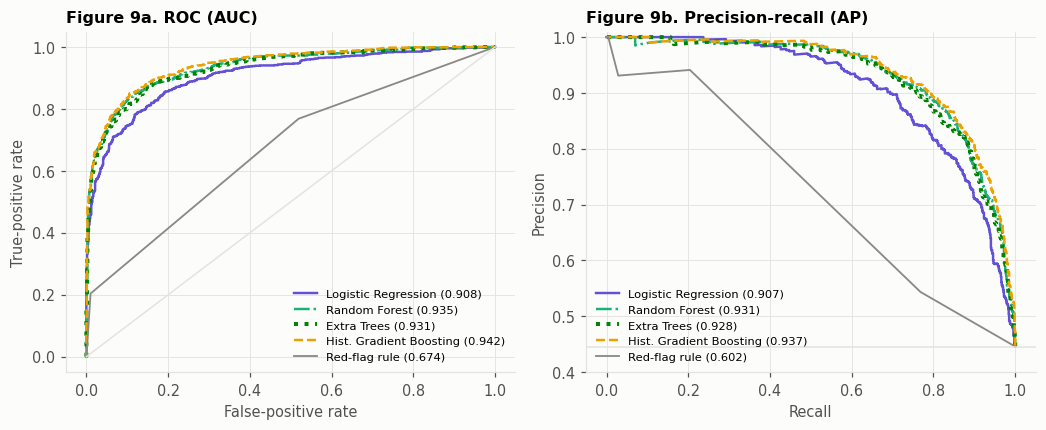

In [23]:
# All tuned models on the test set. Shown for context only: the selection above was already final.
curves, all_test = {}, []
for name, est in tuned.items():
    m = final_dev if name == selected else clone(est).fit(X_dev, y_dev)
    p = m.predict_proba(X_test)[:, 1]
    curves[name] = p
    all_test.append({"model": name, "selected": name == selected, **binary_metrics(y_test, p)})
rule = RedFlagBaseline().fit(X_dev, y_dev)
p_rule = rule.predict_proba(X_test)[:, 1]
all_test.append({"model": "red_flag_rule", "selected": False, **binary_metrics(y_test, p_rule)})
all_test = save_table(pd.DataFrame(all_test).sort_values("pr_auc", ascending=False), "t17_all_models_on_test")
display(all_test[["model", "selected", "pr_auc", "roc_auc", "f1", "accuracy", "precision", "recall", "mcc"]])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 4.0))
for name, p in curves.items():
    st = MODEL_STYLE[name]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    lw = 2.6 if name == selected else 1.6
    a1.plot(fpr, tpr, color=st["color"], ls=st["ls"], lw=lw, label=f"{st['label']} ({roc_auc_score(y_test, p):.3f})")
    a2.plot(rec, prec, color=st["color"], ls=st["ls"], lw=lw, label=f"{st['label']} ({average_precision_score(y_test, p):.3f})")
fpr, tpr, _ = roc_curve(y_test, p_rule)
prec, rec, _ = precision_recall_curve(y_test, p_rule)
a1.plot(fpr, tpr, color=NEUTRAL, lw=1.2, label=f"Red-flag rule ({roc_auc_score(y_test, p_rule):.3f})")
a2.plot(rec, prec, color=NEUTRAL, lw=1.2, label=f"Red-flag rule ({average_precision_score(y_test, p_rule):.3f})")
a1.plot([0, 1], [0, 1], color=GRID, lw=1)
a2.axhline(y_test.mean(), color=GRID, lw=1)
a1.set(xlabel="False-positive rate", ylabel="True-positive rate", title="Figure 9a. ROC (AUC)")
a2.set(xlabel="Recall", ylabel="Precision", title="Figure 9b. Precision-recall (AP)", ylim=(0.4, 1.01))
a1.legend(loc="lower right", fontsize=7.5)
a2.legend(loc="lower left", fontsize=7.5)
save_fig(fig, "fig09_roc_pr_curves")

## 11. Thresholds, risk bands and calibration

The backend turns the phishing probability *p* into three user-facing bands: **likely benign** (*p* < 0.5), **suspicious** (0.5 ≤ *p* < 0.8) and **high risk** (*p* ≥ 0.8). It also shows an **uncertain** flag for 0.35 ≤ *p* ≤ 0.65. Here we check empirically whether these bands mean what the interface says they mean, and whether *p* is calibrated.

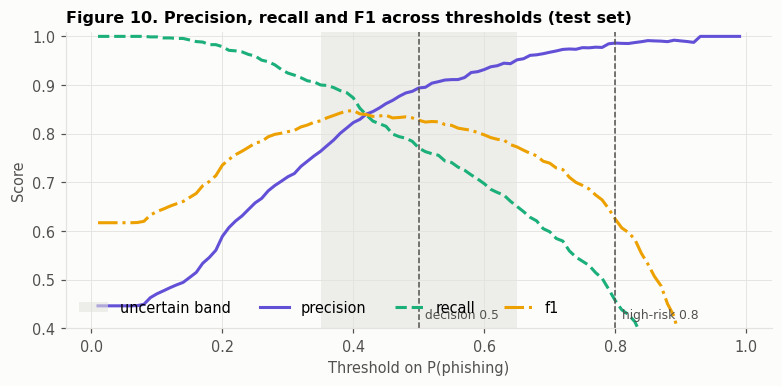

,urls,observed_phishing_rate,mean_predicted,share_of_test
band,,,,
likely_benign,1299,0.1663,0.2498,0.6156
suspicious,375,0.7867,0.6634,0.1777
high_risk,436,0.9862,0.9025,0.2066


Uncertain flag raised on 22.1% of test URLs; accuracy inside the band 0.620 vs outside 0.924. Best-F1 threshold on test: 0.40 (reported, not deployed).


In [24]:
grid = np.linspace(0.01, 0.99, 99)
thr = pd.DataFrame([{"threshold": t, "precision": precision_score(y_test, p_test >= t, zero_division=0),
                     "recall": recall_score(y_test, p_test >= t), "f1": f1_score(y_test, p_test >= t)} for t in grid])
best_f1_threshold = thr.loc[thr["f1"].idxmax(), "threshold"]
save_table(thr, "t18_threshold_sweep")

fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.axvspan(0.35, 0.65, color=GRID, alpha=0.6, lw=0, label="uncertain band")
for col, c, ls in zip(["precision", "recall", "f1"], ["#6250d6", "#1baf7a", "#eda100"], ["-", "--", "-."]):
    ax.plot(thr["threshold"], thr[col], color=c, ls=ls, label=col)
for t, lab in ((0.5, "decision 0.5"), (0.8, "high-risk 0.8")):
    ax.axvline(t, color=INK_2, lw=1, ls="--")
    ax.text(t + 0.01, 0.42, lab, color=INK_2, fontsize=8)
ax.set(xlabel="Threshold on P(phishing)", ylabel="Score", ylim=(0.4, 1.01),
       title="Figure 10. Precision, recall and F1 across thresholds (test set)")
ax.legend(loc="lower left", ncol=4)
save_fig(fig, "fig10_threshold_sweep")

bands = pd.cut(p_test, [-0.001, 0.5, 0.8, 1.0], labels=["likely_benign", "suspicious", "high_risk"])
band_table = (pd.DataFrame({"band": bands, "y": y_test, "p": p_test}).groupby("band", observed=False)
              .agg(urls=("y", "size"), observed_phishing_rate=("y", "mean"), mean_predicted=("p", "mean")))
band_table["share_of_test"] = band_table["urls"] / len(y_test)
unc = (p_test >= 0.35) & (p_test <= 0.65)
acc_in = ((p_test[unc] >= 0.5) == y_test[unc]).mean() if unc.any() else np.nan
acc_out = ((p_test[~unc] >= 0.5) == y_test[~unc]).mean()
save_table(band_table.reset_index(), "t19_risk_band_validation")
display(band_table)
print(f"Uncertain flag raised on {unc.mean():.1%} of test URLs; accuracy inside the band {acc_in:.3f} "
      f"vs outside {acc_out:.3f}. Best-F1 threshold on test: {best_f1_threshold:.2f} (reported, not deployed).")

,model,brier,ece,pr_auc
0,"extra_trees (deployed, uncalibrated)",0.1115,0.1036,0.9276
1,extra_trees + isotonic calibration,0.1025,0.0441,0.9274


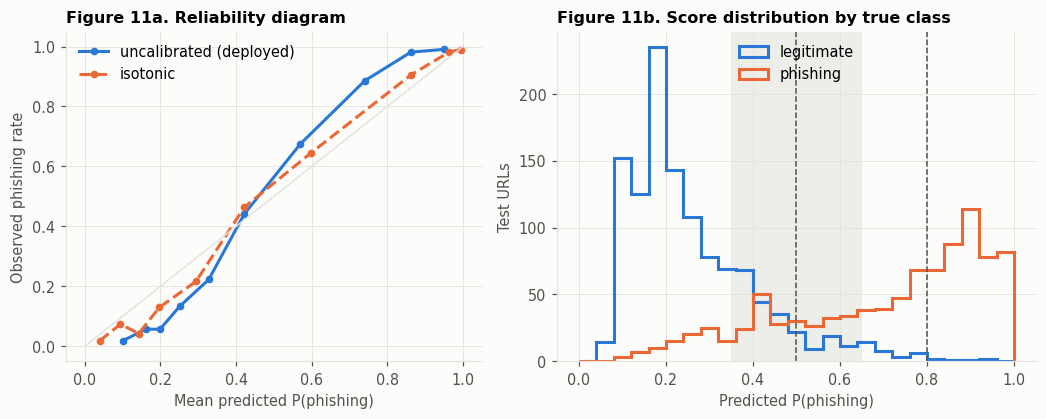

In [25]:
def ece(y_true, p, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1)
    return sum(abs(y_true[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean()
               for b in range(bins) if (idx == b).any())

calibrated = CalibratedClassifierCV(clone(tuned[selected]), method="isotonic", cv=cv_splits).fit(X_dev, y_dev)
p_cal = calibrated.predict_proba(X_test)[:, 1]
calib = pd.DataFrame([
    {"model": f"{selected} (deployed, uncalibrated)", "brier": brier_score_loss(y_test, p_test),
     "ece": ece(y_test, p_test), "pr_auc": average_precision_score(y_test, p_test)},
    {"model": f"{selected} + isotonic calibration", "brier": brier_score_loss(y_test, p_cal),
     "ece": ece(y_test, p_cal), "pr_auc": average_precision_score(y_test, p_cal)},
])
save_table(calib, "t20_calibration")
display(calib)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.9), gridspec_kw={"width_ratios": [1, 1.15]})
for p, lab, c, ls in ((p_test, "uncalibrated (deployed)", "#2a78d6", "-"), (p_cal, "isotonic", "#eb6834", "--")):
    frac, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    a1.plot(mean_pred, frac, marker="o", ms=4, color=c, ls=ls, label=lab)
a1.plot([0, 1], [0, 1], color=GRID, lw=1)
a1.set(xlabel="Mean predicted P(phishing)", ylabel="Observed phishing rate", title="Figure 11a. Reliability diagram")
a1.legend(loc="upper left")
bins_h = np.linspace(0, 1, 26)
for c in (0, 1):
    a2.hist(p_test[y_test == c], bins=bins_h, histtype="step", lw=2, color=CLASS_COLORS[c], label=CLASS_NAMES[c])
for t in (0.5, 0.8):
    a2.axvline(t, color=INK_2, lw=1, ls="--")
a2.axvspan(0.35, 0.65, color=GRID, alpha=0.6, lw=0)
a2.set(xlabel="Predicted P(phishing)", ylabel="Test URLs", title="Figure 11b. Score distribution by true class")
a2.legend(loc="upper center")
save_fig(fig, "fig11_calibration")

## 12. Leakage study: how optimistic are random splits?

The selected configuration and logistic regression are evaluated on the **full** cleaned corpus under three protocols:

* **Random:** 5-fold stratified CV that ignores domains, the most common practice in the literature.
* **Official split:** the dataset authors' own train/test files, after our de-duplication.
* **Domain-grouped:** 5-fold stratified *group* CV, the protocol used throughout this study.

In [26]:
random_splits = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y))
grouped_splits = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y, groups))
seen_share = np.mean([np.isin(groups[va], groups[tr]).mean() for tr, va in random_splits])
hf_tr = np.where(data["hf_split"].to_numpy() == "train")[0]
hf_te = np.where(data["hf_split"].to_numpy() == "test")[0]

leak_rows = []
for name in dict.fromkeys([selected, "logistic_regression"]):
    for proto, splits in (("random 5-fold", random_splits), ("official train/test", [(hf_tr, hf_te)]),
                          ("domain-grouped 5-fold", grouped_splits)):
        res = cross_validate(tuned[name], X, y, cv=splits, scoring={"pr_auc": "average_precision", "f1": "f1",
                                                                   "accuracy": "accuracy"}, n_jobs=N_JOBS)
        leak_rows.append({"model": name, "protocol": proto, "pr_auc": res["test_pr_auc"].mean(),
                          "f1": res["test_f1"].mean(), "accuracy": res["test_accuracy"].mean()})
leakage = pd.DataFrame(leak_rows)
ref = leakage[leakage["protocol"] == "domain-grouped 5-fold"].set_index("model")
for m in ("pr_auc", "f1", "accuracy"):
    leakage[f"{m}_inflation_vs_grouped"] = leakage.apply(lambda r: r[m] - ref.loc[r["model"], m], axis=1)
save_table(leakage, "t21_leakage_study")
display(leakage)
print(f"Under random splitting, on average {seen_share:.1%} of validation URLs come from a domain "
      f"already present in the training folds.")

,model,protocol,pr_auc,f1,accuracy,pr_auc_inflation_vs_grouped,f1_inflation_vs_grouped,accuracy_inflation_vs_grouped
0,extra_trees,random 5-fold,0.9411,0.8430,0.8549,0.0396,0.0412,0.0312
1,extra_trees,official train/test,0.9384,0.8402,0.8538,0.0369,0.0384,0.0302
2,extra_trees,domain-grouped 5-fold,0.9015,0.8018,0.8236,0.0000,0.0000,0.0000
3,logistic_regression,random 5-fold,0.9018,0.7862,0.8034,0.0200,0.0140,0.0057
4,logistic_regression,official train/test,0.9009,0.7811,0.8005,0.0191,0.0088,0.0028
5,logistic_regression,domain-grouped 5-fold,0.8818,0.7723,0.7977,0.0000,0.0000,0.0000


Under random splitting, on average 49.3% of validation URLs come from a domain already present in the training folds.


## 13. Out-of-source generalisation

Two probes use data from **different sources** that played no part in training or selection:

* **OpenPhish.** Live phishing URLs from a different feed and a later collection time. Every URL is phishing, so the share flagged is a *recall proxy*.
* **Majestic Million.** The 1,000 most-linked registrable domains, written as `https://<domain>`. These are overwhelmingly legitimate, so the share flagged is a *false-positive-rate proxy*.

Both are indicative probes, not benchmarks: neither sample is labelled by hand. URLs that also occur in the training corpus are reported separately.

In [27]:
corpus_canon = set(data["canonical"])
corpus_legit_domains = set(data.loc[data["label"] == 0, "domain"])

def probe_frame(url_list):
    keep = [u for u in dict.fromkeys(url_list) if parses(u) and len(u) <= MAX_URL_LEN]
    return pd.DataFrame({"url": keep, "canonical": [normalise_url_for_dedup(u) for u in keep]})

def run_probes(model):
    op = probe_frame([l.strip() for l in (RAW_DIR / "openphish_feed.txt").read_text(encoding="utf-8").splitlines()
                      if l.strip().startswith("http")])
    op["in_corpus"] = op["canonical"].isin(corpus_canon)
    op["p"] = model.predict_proba(features_of(op["url"]))[:, 1]
    maj = pd.read_csv(RAW_DIR / "majestic_million.csv", usecols=["GlobalRank", "Domain"], nrows=1000)
    mj = probe_frame([f"https://{d.strip().lower()}" for d in maj["Domain"].astype(str) if "." in d])
    mj["domain"] = mj["url"].map(domain_group)
    mj["in_corpus"] = mj["domain"].isin(corpus_legit_domains)
    mj["p"] = model.predict_proba(features_of(mj["url"]))[:, 1]
    return op, mj

op, mj = run_probes(final_dev)
rows = []
for label, frame, metric in (("OpenPhish (all phishing)", op, "recall proxy"),
                             ("Majestic top 1,000 (legitimate)", mj, "false-positive-rate proxy")):
    for subset, f in (("all", frame), ("not in training corpus", frame[~frame["in_corpus"]])):
        k, n = int((f["p"] >= 0.5).sum()), len(f)
        lo, hi = wilson_ci(k, n)
        rows.append({"probe": label, "subset": subset, "metric": metric, "urls": n, "flagged": k,
                     "rate": k / n if n else np.nan, "wilson95_low": lo, "wilson95_high": hi})
probes = save_table(pd.DataFrame(rows), "t22_out_of_source_probes")
display(probes)

fp_domains = mj[mj["p"] >= 0.5].sort_values("p", ascending=False).head(15)[["url", "p"]]
save_table(fp_domains, "t23_majestic_false_positives")
print("Popular legitimate domains flagged as phishing (top 15 by P(phishing)):")
fp_domains

,probe,subset,metric,urls,flagged,rate,wilson95_low,wilson95_high
0,OpenPhish (all phishing),all,recall proxy,300,237,0.7900,0.7404,0.8323
1,OpenPhish (all phishing),not in training corpus,recall proxy,300,237,0.7900,0.7404,0.8323
2,"Majestic top 1,000 (legitimate)",all,false-positive-rate proxy,1000,28,0.0280,0.0194,0.0402
3,"Majestic top 1,000 (legitimate)",not in training corpus,false-positive-rate proxy,720,25,0.0347,0.0236,0.0508


Popular legitimate domains flagged as phishing (top 15 by P(phishing)):


,url,p
10,https://w2rt6byl5nf1opmc-a.com,0.7863
560,https://shorturl.at,0.7518
105,https://tinyurl.com,0.7487
869,https://outlook.office365.com,0.7328
96,https://t.co,0.7297
725,https://cutt.ly,0.7235
438,https://lnkd.in,0.7235
16,https://goo.gl,0.7234
40,https://bit.ly,0.7213
205,https://outlook.office.com,0.6352


## 14. Interpretability

**Global.** Permutation importance measures how much test PR-AUC drops when one feature's values are shuffled (20 repeats). Unlike impurity-based importance, it is computed on held-out data and is not biased towards high-cardinality features. Partial dependence plots show the average effect of the most important features.

**Local.** The backend's `compute_model_evidence` decomposes every individual prediction exactly. We verify that claim on a sample of test URLs: the contributions plus the bias must reproduce `predict_proba`.

Rank agreement, permutation vs impurity importance: Spearman ρ = 0.91 (p = 4.6e-13)


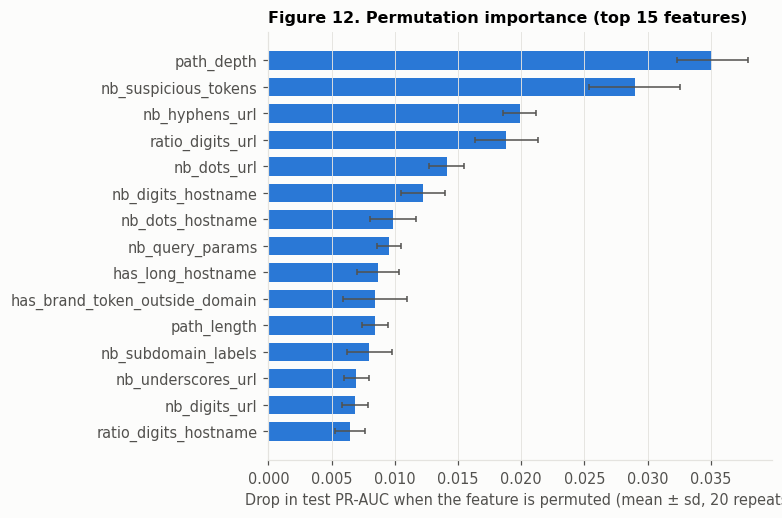

,feature,group,perm_importance_mean,perm_importance_std,impurity_importance
0,path_depth,"scheme, path and query",0.0351,0.0028,0.0691
1,nb_suspicious_tokens,curated lexicons,0.0290,0.0036,0.0691
2,nb_hyphens_url,character composition,0.0199,0.0013,0.0566
3,ratio_digits_url,character composition,0.0188,0.0025,0.0868
4,nb_dots_url,character composition,0.0141,0.0014,0.0429
5,nb_digits_hostname,character composition,0.0122,0.0017,0.0395
6,nb_dots_hostname,character composition,0.0099,0.0018,0.0644
7,nb_query_params,"scheme, path and query",0.0095,0.0010,0.0332
8,has_long_hostname,length,0.0087,0.0017,0.0629
9,has_brand_token_outside_domain,curated lexicons,0.0085,0.0025,0.0295


In [28]:
pi = permutation_importance(final_dev, X_test, y_test, scoring="average_precision", n_repeats=20,
                            random_state=SEED, n_jobs=N_JOBS)
imp = pd.DataFrame({"feature": FEATURE_NAMES, "group": [GROUP_OF[f] for f in FEATURE_NAMES],
                    "perm_importance_mean": pi.importances_mean, "perm_importance_std": pi.importances_std})
clf = final_dev.named_steps["clf"]
if hasattr(clf, "feature_importances_"):
    imp["impurity_importance"] = clf.feature_importances_
if hasattr(clf, "coef_"):
    imp["std_coefficient"] = clf.coef_[0]
imp = imp.sort_values("perm_importance_mean", ascending=False).reset_index(drop=True)
save_table(imp, "t24_feature_importance")
if "impurity_importance" in imp:
    r_s, p_s = stats.spearmanr(imp["perm_importance_mean"], imp["impurity_importance"])
    print(f"Rank agreement, permutation vs impurity importance: Spearman ρ = {r_s:.2f} (p = {p_s:.1e})")

top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.barh(top["feature"], top["perm_importance_mean"], xerr=top["perm_importance_std"], color="#2a78d6",
        height=0.7, error_kw=dict(ecolor=INK_2, lw=1, capsize=2))
ax.set_xlabel("Drop in test PR-AUC when the feature is permuted (mean ± sd, 20 repeats)")
ax.set_title("Figure 12. Permutation importance (top 15 features)")
ax.grid(axis="y", visible=False)
save_fig(fig, "fig12_permutation_importance")
imp.head(15)

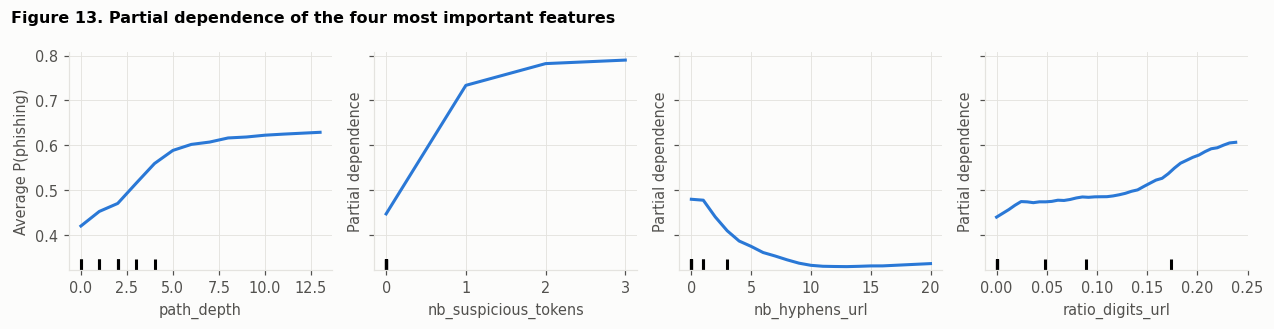

In [29]:
top4 = imp["feature"].head(4).tolist()
fig, axes = plt.subplots(1, 4, figsize=(11.5, 3.0), sharey=True)
PartialDependenceDisplay.from_estimator(final_dev, X_test, top4, kind="average", grid_resolution=40, ax=axes,
                                        line_kw=dict(color="#2a78d6", lw=2), n_jobs=N_JOBS)
axes[0].set_ylabel("Average P(phishing)")
fig.suptitle("Figure 13. Partial dependence of the four most important features", x=0.01, ha="left",
             fontweight="bold", fontsize=10.5)
save_fig(fig, "fig13_partial_dependence")

In [30]:
sample = np.random.default_rng(SEED).choice(len(X_test), size=min(500, len(X_test)), replace=False)
errors, methods = [], set()
t0 = time.perf_counter()
for i in sample:
    ev = compute_model_evidence(final_dev, X_test.iloc[i].to_dict())
    methods.add(ev["method"])
    pc = ev["probability_check"]
    errors.append(abs(pc["decomposition_sum"] - pc["predict_proba"]))
explain_ms = (time.perf_counter() - t0) / len(sample) * 1e3
exactness = {"urls_checked": len(sample), "methods": sorted(methods), "max_abs_error": float(np.max(errors)),
             "all_exact_within_1e-6": bool(np.max(errors) <= 1e-6), "mean_explanation_ms": explain_ms}
save_table(pd.DataFrame([exactness]), "t25_explanation_exactness")
exactness

{'urls_checked': 500,
 'methods': ['tree_path'],
 'max_abs_error': 0.0,
 'all_exact_within_1e-6': True,
 'mean_explanation_ms': 113.94322340004146}

True positive   hxxp://107[.]180[.]44[.]78/login[.]php?cmd=login_submit&id=9935941aa736b1f240b52ffbec44d57e993…
True negative   hxxp://www[.]fonearena[.]com/blog/110043/vh1-app-released-for-android-iphone-ipad-and-windows-…


False negative  hxxps://news[.]acscinc[.]com/


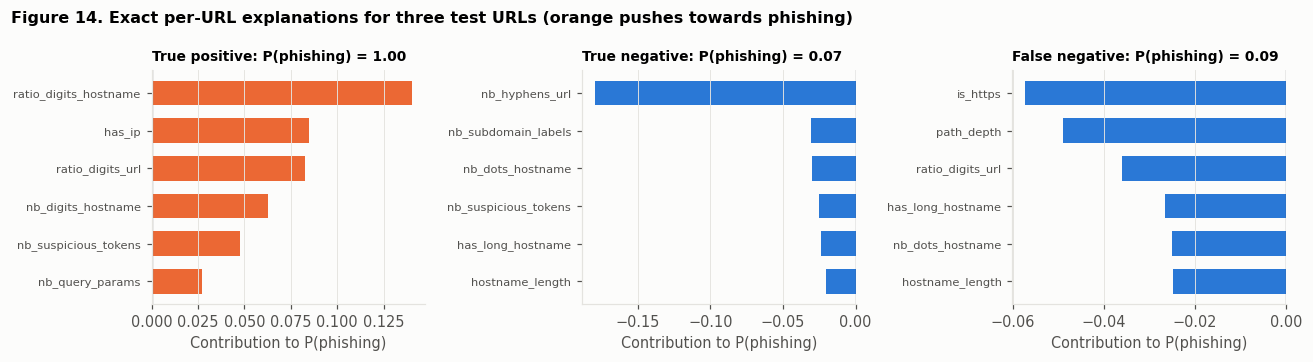

In [31]:
def pick(mask, key):
    idx = np.where(mask)[0]
    return idx[np.argmax(key[idx])] if len(idx) else None

cases = [("True positive", pick((y_test == 1) & (p_test >= 0.5), p_test)),
         ("True negative", pick((y_test == 0) & (p_test < 0.5), -p_test)),
         ("False negative", pick((y_test == 1) & (p_test < 0.5), -p_test))]
cases = [(t, i) for t, i in cases if i is not None]
fig, axes = plt.subplots(1, len(cases), figsize=(4.0 * len(cases), 3.3))
axes = np.atleast_1d(axes)
for ax, (title, i) in zip(axes, cases):
    ev = compute_model_evidence(final_dev, X_test.iloc[i].to_dict())
    contrib = pd.Series(ev["contributions"]).sort_values(key=np.abs, ascending=False).head(6).iloc[::-1]
    ax.barh(contrib.index, contrib.values, color=[CLASS_COLORS[1] if v > 0 else CLASS_COLORS[0] for v in contrib],
            height=0.65)
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.set_title(f"{title}: P(phishing) = {p_test[i]:.2f}", fontsize=9)
    ax.set_xlabel("Contribution to P(phishing)" if ev["method"] == "tree_path" else "Contribution (log-odds)")
    ax.tick_params(axis="y", labelsize=7.5)
    ax.grid(axis="y", visible=False)
    print(f"{title:15s} {short(defang(urls_test[i]), 95)}")
fig.suptitle("Figure 14. Exact per-URL explanations for three test URLs (orange pushes towards phishing)",
             x=0.01, ha="left", fontweight="bold", fontsize=10.5)
save_fig(fig, "fig14_local_explanations")

## 15. Ablation and learning curve

**Feature-group ablation.** The selected configuration is retrained on the same grouped folds, (a) without each feature group and (b) with that group alone. Large drops identify the families the model cannot do without.

**Learning curve.** This shows whether more labelled data would still help.

All 33 features: PR-AUC 0.9114


,group,n_features,pr_auc_without_group,drop_when_removed,pr_auc_group_only
1,character composition,13,0.8549,0.0565,0.8726
4,curated lexicons,5,0.8963,0.0151,0.6158
3,"scheme, path and query",4,0.9002,0.0112,0.6976
0,length,5,0.9027,0.0087,0.7393
2,host structure,6,0.9105,0.0009,0.6609


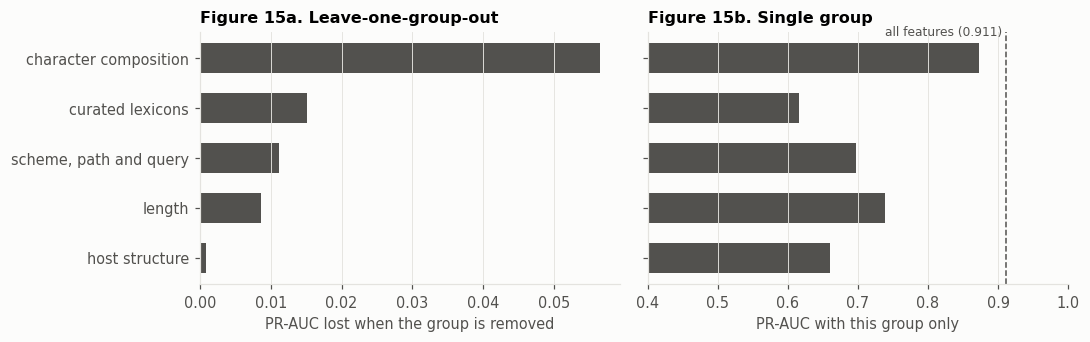

In [32]:
def grouped_pr(est, cols):
    return cross_validate(clone(est), X_dev[cols], y_dev, cv=cv_splits, scoring="average_precision",
                          n_jobs=N_JOBS)["test_score"]

full_scores = grouped_pr(tuned[selected], FEATURE_NAMES)
abl = []
for g, feats in FEATURE_GROUPS.items():
    without = grouped_pr(tuned[selected], [f for f in FEATURE_NAMES if f not in feats])
    only = grouped_pr(tuned[selected], feats)
    abl.append({"group": g, "n_features": len(feats), "pr_auc_without_group": without.mean(),
                "drop_when_removed": full_scores.mean() - without.mean(), "pr_auc_group_only": only.mean()})
ablation = save_table(pd.DataFrame(abl).sort_values("drop_when_removed", ascending=False), "t26_feature_group_ablation")
print(f"All 33 features: PR-AUC {full_scores.mean():.4f}")
display(ablation)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
ab = ablation.iloc[::-1]
a1.barh(ab["group"], ab["drop_when_removed"], color=INK_2, height=0.6)
a1.set(xlabel="PR-AUC lost when the group is removed", title="Figure 15a. Leave-one-group-out")
a2.barh(ab["group"], ab["pr_auc_group_only"], color=INK_2, height=0.6)
a2.axvline(full_scores.mean(), color=INK_2, ls="--", lw=1)
a2.text(full_scores.mean() - 0.005, len(ab) - 0.55, f"all features ({full_scores.mean():.3f})", color=INK_2,
        fontsize=8, ha="right")
a2.set(xlabel="PR-AUC with this group only", title="Figure 15b. Single group", xlim=(0.4, 1.0))
for a in (a1, a2):
    a.grid(axis="y", visible=False)
save_fig(fig, "fig15_feature_group_ablation")

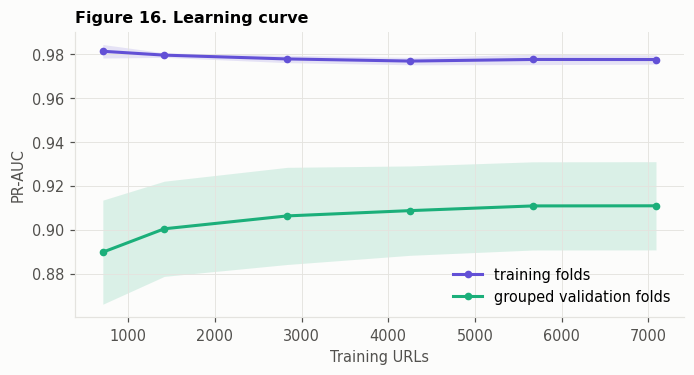

,training_urls,train_pr_auc,cv_pr_auc,cv_pr_auc_std
0,708,0.9813,0.8897,0.0237
1,1417,0.9796,0.9004,0.0217
2,2835,0.9778,0.9063,0.0221
3,4253,0.9769,0.9087,0.0204
4,5671,0.9776,0.9108,0.0201
5,7089,0.9776,0.9109,0.0201


In [33]:
sizes, tr_scores, va_scores = learning_curve(clone(tuned[selected]), X_dev, y_dev, groups=g_dev, cv=CV,
                                             train_sizes=[0.1, 0.2, 0.4, 0.6, 0.8, 1.0],
                                             scoring="average_precision", n_jobs=N_JOBS, shuffle=True,
                                             random_state=SEED)
lc = pd.DataFrame({"training_urls": sizes, "train_pr_auc": tr_scores.mean(1), "cv_pr_auc": va_scores.mean(1),
                   "cv_pr_auc_std": va_scores.std(1)})
save_table(lc, "t27_learning_curve")
fig, ax = plt.subplots(figsize=(6.4, 3.5))
for col, c, lab, sd in (("train_pr_auc", "#6250d6", "training folds", tr_scores.std(1)),
                        ("cv_pr_auc", "#1baf7a", "grouped validation folds", va_scores.std(1))):
    ax.plot(lc["training_urls"], lc[col], marker="o", ms=4, color=c, label=lab)
    ax.fill_between(lc["training_urls"], lc[col] - sd, lc[col] + sd, color=c, alpha=0.15, lw=0)
ax.set(xlabel="Training URLs", ylabel="PR-AUC", title="Figure 16. Learning curve")
ax.legend(loc="lower right")
save_fig(fig, "fig16_learning_curve")
lc

## 16. Error analysis

Error rates are broken down by URL segment: false-positive rate (FPR) among legitimate URLs and false-negative rate (FNR) among phishing URLs. Segments with fewer than 30 URLs of a class are not reported for that class.

In [34]:
pred_test = (p_test >= 0.5).astype(int)
err = X_test.copy()
err["y"], err["pred"], err["url"] = y_test, pred_test, urls_test
err["tld"] = [(parse_url(u).hostname or "").rsplit(".", 1)[-1].lower() for u in urls_test]
err["length_quartile"] = pd.qcut(err["url_length"], 4, labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"])

def segment_rates(col, label=None, keep=None):
    out = []
    for val, g in err.groupby(col, observed=True):
        if keep is not None and val not in keep:
            continue
        legit, phish = g[g["y"] == 0], g[g["y"] == 1]
        out.append({"segment": label or col, "value": str(val),
                    "legit_urls": len(legit), "fpr": (legit["pred"] == 1).mean() if len(legit) >= 30 else np.nan,
                    "phish_urls": len(phish), "fnr": (phish["pred"] == 0).mean() if len(phish) >= 30 else np.nan})
    return out

top_test_tlds = err["tld"].value_counts().head(8).index
seg = pd.DataFrame(segment_rates("is_https", "HTTPS") + segment_rates("has_ip", "IP host")
                   + segment_rates("length_quartile", "URL length") + segment_rates("tld", "TLD", set(top_test_tlds))
                   + segment_rates("has_brand_token_outside_domain", "brand outside domain")
                   + segment_rates("has_suspicious_tld", "high-abuse TLD"))
overall = {"fpr": ((err["y"] == 0) & (err["pred"] == 1)).sum() / (err["y"] == 0).sum(),
           "fnr": ((err["y"] == 1) & (err["pred"] == 0)).sum() / (err["y"] == 1).sum()}
save_table(seg, "t28_error_rates_by_segment")
print(f"Overall test FPR {overall['fpr']:.3f}, FNR {overall['fnr']:.3f}")
seg

Overall test FPR 0.074, FNR 0.230


,segment,value,legit_urls,fpr,phish_urls,fnr
0,HTTPS,0.0,600,0.1033,658,0.2432
1,HTTPS,1.0,569,0.0422,283,0.1979
2,IP host,0.0,1169,0.0736,924,0.2338
3,IP host,1.0,0,NaN,17,NaN
4,URL length,Q1 shortest,385,0.0312,143,0.3636
5,URL length,Q2,301,0.1362,244,0.3156
6,URL length,Q3,313,0.0671,203,0.3202
7,URL length,Q4 longest,170,0.0706,351,0.0627
8,TLD,au,12,NaN,15,NaN
9,TLD,com,634,0.0789,524,0.2042


In [35]:
def top_reasons(i, k=3):
    ev = compute_model_evidence(final_dev, X_test.iloc[i].to_dict())
    c = pd.Series(ev["contributions"]).sort_values(key=np.abs, ascending=False).head(k)
    return ", ".join(f"{f} ({v:+.2f})" for f, v in c.items())

fn_idx = np.where((y_test == 1) & (pred_test == 0))[0]
fp_idx = np.where((y_test == 0) & (pred_test == 1))[0]
fn_cases = pd.DataFrame([{"url (defanged)": short(defang(urls_test[i]), 80), "p_phishing": p_test[i],
                          "strongest contributions": top_reasons(i)} for i in fn_idx[np.argsort(p_test[fn_idx])][:10]])
fp_cases = pd.DataFrame([{"url (defanged)": short(defang(urls_test[i]), 80), "p_phishing": p_test[i],
                          "strongest contributions": top_reasons(i)} for i in fp_idx[np.argsort(-p_test[fp_idx])][:10]])
save_table(fn_cases, "t29_most_confident_false_negatives")
save_table(fp_cases, "t30_most_confident_false_positives")
display(Markdown("**Most confident misses (phishing scored as benign)**"))
display(fn_cases)
display(Markdown("**Most confident false alarms (legitimate scored as phishing)**"))
fp_cases

**Most confident misses (phishing scored as benign)**

,url (defanged),p_phishing,strongest contributions
0,hxxps://news[.]acscinc[.]com/,0.0856,"is_https (-0.06), path_depth (-0.05), ratio_digits_url (-0.04)"
1,hxxps://elastim[.]netlify[.]app/,0.1018,"is_https (-0.06), path_depth (-0.05), ratio_digits_url (-0.04)"
2,hxxps://bibila[.]com[.]au/,0.1067,"is_https (-0.06), path_depth (-0.05), ratio_digits_url (-0.04)"
3,hxxps://sdek[.]msk[.]ru,0.1286,"is_https (-0.05), path_depth (-0.05), ratio_digits_url (-0.04)"
4,hxxps://mbmaquila[.]com[.]py/home,0.1461,"is_https (-0.07), hostname_length (-0.04), ratio_digits_url (-0.04)"
5,hxxps://hmlkl[.]codesandbox[.]io/-=_=-=a-s=-a=-=-+_+[.]html,0.1471,"nb_hyphens_url (-0.10), is_https (-0.04), ratio_digits_url (-0.04)"
6,hxxps://jcsgt[.]codesandbox[.]io/,0.1498,"is_https (-0.05), path_depth (-0.04), ratio_digits_url (-0.04)"
7,hxxp://www[.]dalla[.]eu/,0.1505,"path_depth (-0.06), hostname_entropy (-0.06), is_https (+0.04)"
8,hxxp://p[.]wpage[.]cc/,0.1540,"path_depth (-0.06), is_https (+0.04), hostname_entropy (-0.04)"
9,hxxps://transfer[.]paxful[.]boubit[.]com/,0.1544,"hostname_entropy (+0.07), is_https (-0.07), has_long_hostname (-0.05)"


**Most confident false alarms (legitimate scored as phishing)**

,url (defanged),p_phishing,strongest contributions
0,hxxps://www[.]nextmillenniumcatalog[.]com/Responsive/ApplyStepOneNS[.]aspx?sfid…,0.9283,"nb_query_params (+0.11), query_length (+0.09), ratio_digits_url (+0.09)"
1,hxxp://www[.]isitdownrightnow[.]com/update[.]microsoft[.]com[.]html,0.9228,"has_brand_token_outside_domain (+0.27), nb_suspicious_tokens (+0.18), nb_dots_url (+0.07)"
2,hxxp://back[.]dog/auth/login,0.8851,"nb_suspicious_tokens (+0.26), nb_subdomain_labels (+0.08), nb_dots_hostname (+0.07)"
3,hxxp://bectechnologies[.]net/wordpress/wp-content/uploads/2015/08/BEC_8920NE_QS…,0.8403,"ratio_digits_url (+0.12), nb_dots_hostname (+0.10), nb_subdomain_labels (+0.09)"
4,hxxp://packetlife[.]net/media/library/32/NAT[.]pdf,0.8398,"nb_subdomain_labels (+0.13), nb_dots_hostname (+0.11), path_depth (+0.07)"
5,hxxp://4pda[.]ru/tag/microsoft_windows_10_creators_update/,0.8215,"has_brand_token_outside_domain (+0.19), nb_suspicious_tokens (+0.15), nb_dots_hostname..."
6,hxxp://stattrek[.]com/statistics/dictionary[.]aspx?definition=standard%20error,0.7947,"nb_subdomain_labels (+0.12), nb_dots_hostname (+0.10), nb_query_params (+0.10)"
7,hxxp://tjscott[.]net/firewall/stateful[.]ins[.]htm,0.7886,"nb_subdomain_labels (+0.13), nb_dots_hostname (+0.13), nb_dots_url (+0.11)"
8,hxxp://eudesign[.]com/mnems/portstar[.]htm,0.7868,"nb_subdomain_labels (+0.13), nb_dots_hostname (+0.13), nb_dots_url (+0.07)"
9,hxxp://www[.]google[.]co[.]id/patents/US6219419,0.7806,"has_brand_token_outside_domain (+0.32), ratio_digits_url (+0.06), hostname_length (-0.03)"


## 17. Computational cost

Latency is measured end to end and single-threaded, the way the API serves one request: feature extraction, prediction and exact explanation for one URL.

In [36]:
serving = clone(tuned[selected]).fit(X_dev, y_dev)
if "n_jobs" in serving.named_steps["clf"].get_params():
    serving.set_params(clf__n_jobs=1)
probe_path = PROCESSED_DIR / "_size_probe.joblib"
joblib.dump(serving, probe_path, compress=3)
size_mb = probe_path.stat().st_size / 1e6
probe_path.unlink()

lat_pred, lat_expl = [], []
for u in urls_test[:400]:
    t0 = time.perf_counter()
    feats = extract_features(u)
    xi = pd.DataFrame([[float(feats[f]) for f in FEATURE_NAMES]], columns=FEATURE_NAMES)
    serving.predict_proba(xi)
    t1 = time.perf_counter()
    compute_model_evidence(serving, feats)
    lat_pred.append((t1 - t0) * 1e3)
    lat_expl.append((time.perf_counter() - t1) * 1e3)
cost = pd.DataFrame([
    {"quantity": "training time on development set (s, all cores)", "value": fit_seconds_dev},
    {"quantity": "serialised model size (MB, joblib compress=3)", "value": size_mb},
    {"quantity": "feature extraction + prediction, median (ms)", "value": np.median(lat_pred)},
    {"quantity": "feature extraction + prediction, p95 (ms)", "value": np.percentile(lat_pred, 95)},
    {"quantity": "exact explanation, median (ms)", "value": np.median(lat_expl)},
    {"quantity": "exact explanation, p95 (ms)", "value": np.percentile(lat_expl, 95)},
])
save_table(cost, "t31_computational_cost")
cost

,quantity,value
0,"training time on development set (s, all cores)",3.2847
1,"serialised model size (MB, joblib compress=3)",6.1568
2,"feature extraction + prediction, median (ms)",43.9823
3,"feature extraction + prediction, p95 (ms)",73.1826
4,"exact explanation, median (ms)",113.8130
5,"exact explanation, p95 (ms)",181.6874


## 18. Deployment into the backend

The deployed model uses the selected hyperparameters but is **refit on all cleaned data** (development + test). This is standard practice: the reported test metrics estimate the performance of this procedure, and the final fit gains 20% more training data. The out-of-source probes are re-run on the deployed model, because those are the numbers the application displays.

The four artefacts follow the contract in `docs/MODEL_DROPIN.md`. The cell then runs the backend's own validator, which uses the same loader as the API at startup, and fails loudly if the backend would refuse the model.

In [37]:
MODEL_VERSION = "2.0.0"
deployed = clone(tuned[selected])
has_jobs = "n_jobs" in deployed.named_steps["clf"].get_params()
if has_jobs:
    deployed.set_params(clf__n_jobs=N_JOBS)
deployed.fit(X, y)
if has_jobs:
    deployed.set_params(clf__n_jobs=1)          # single-request serving is faster single-threaded
op_d, mj_d = run_probes(deployed)
trained_at = datetime.now(timezone.utc).isoformat()

def api_metrics(m):
    return {k: float(m[k]) for k in ("accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc")} | {
        "specificity": float(m["specificity"]), "mcc": float(m["mcc"]), "brier": float(m["brier"]),
        "confusion_matrix": {k: int(m[k]) for k in ("tn", "fp", "fn", "tp")}}

def jsonable(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)

hyperparameters = {k.replace("clf__", ""): v for k, v in tuned[selected].get_params().items()
                   if k in SEARCH[selected][1]}
snapshot = provenance.set_index("file")
dataset = {
    "source": "pirocheto/phishing-url (Hannousse & Yahiouche corpus, CC-BY-4.0)",
    "retrieved": snapshot.loc["train.parquet", "snapshot_date"],
    "prepared_records": int(len(data)),
    "class_distribution": {"phishing": int((y == 1).sum()), "legitimate": int((y == 0).sum())},
    "sha256": {f: snapshot.loc[f, "sha256"] for f in snapshot.index},
}
metadata = {
    "model_id": "threatlens-phishing-url-classifier",
    "model_version": MODEL_VERSION,
    "trained_at": trained_at,
    "selected_model": selected,
    "selection_reason": reason,
    "sklearn_pipeline": True,
    "sklearn_version": sklearn.__version__,
    "python_version": platform.python_version(),
    "feature_schema_version": FEATURE_SCHEMA_VERSION,
    "classification_bands": {
        "high_risk": {"min_probability": 0.80, "description": "Strong phishing indicators"},
        "suspicious": {"min_probability": 0.50, "description": "Meaningful phishing indicators"},
        "likely_benign": {"min_probability": 0.00, "description": "No dominant phishing signals"},
    },
    "uncertain_band": {"lower": 0.35, "upper": 0.65},
    "positive_class": 1,
    "positive_class_label": "phishing",
    "probability_meaning": ("Estimated model probability for the phishing class from predict_proba. NOT a "
                            "calibrated probability and NOT the probability of criminal activity."),
    "dataset": dataset,
    "training_config": {
        "random_seed": SEED,
        "split": "80/20 domain-disjoint stratified hold-out (StratifiedGroupKFold by registrable domain)",
        "model_selection": f"{N_FOLDS}-fold grouped CV on the development set; 3x{N_FOLDS} repeated grouped CV "
                           "with Nadeau-Bengio corrected t-tests",
        "selection_rule": "exact-explanation models only; highest PR-AUC; prefer logistic regression if within "
                          "0.01 and not significantly worse",
        "hyperparameters": hyperparameters,
        "decision_threshold": DECISION_THRESHOLD,
        "candidates": list(CANDIDATES),
        "deployed_fit": f"refit on all {len(data)} cleaned records after evaluation",
        "class_imbalance_handling": "None required - corpus is approximately balanced",
    },
    "training_notebook": "ml/notebooks/threatlens_phishing_url_detection.ipynb",
    "artifacts": {"model": "phishing_model.joblib", "metrics": "metrics.json", "feature_schema": "feature_schema.json"},
}

op_n, op_k = len(op_d), int((op_d["p"] >= 0.5).sum())
mj_n, mj_k = len(mj_d), int((mj_d["p"] >= 0.5).sum())
metrics = {
    "model_id": metadata["model_id"], "model_version": MODEL_VERSION, "selected_model": selected,
    "trained_at": trained_at, "dataset": dataset,
    "split_sizes": {"train": int(len(y_dev)), "validation": int(len(y_dev)), "test": int(len(y_test)),
                    "cv_folds": N_FOLDS, "scheme": "domain-grouped cross-validation on the development set"},
    "validation_comparison": {n: {m: float(rep[n][m].mean()) for m in REP_SCORING} for n in rep},
    "majority_baseline_validation_accuracy": float(
        default_summary.set_index("model").loc["majority_baseline", "accuracy_mean"]),
    "test_metrics": api_metrics(test_m),
    "test_metrics_ci95": {r.metric: [float(r.ci95_low), float(r.ci95_high)] for r in test_table.itertuples()},
    "domain_grouped_evaluation": {
        "description": ("The held-out test set is domain-disjoint: no registrable domain appears in both the "
                        "training data and the test set, so these are strict, leakage-free test metrics. See "
                        "random_split_comparison for how much a random split would have inflated them."),
        "n_train": int(len(y_dev)), "n_holdout": int(len(y_test)),
        "n_unique_domains_holdout": int(len(set(g_test))), "metrics": api_metrics(test_m),
    },
    "random_split_comparison": leakage.to_dict(orient="records"),
    "calibration": {"brier": float(test_m["brier"]), "ece": float(ece(y_test, p_test))},
    "explainability": {"method": sorted(methods)[0], **{k: v for k, v in exactness.items() if k != "methods"},
                       "explainability_cost_pr_auc": float(explainability_cost), "best_overall_model": best_overall},
    "out_of_source_checks": {
        f"openphish_feed_{op_n}": {
            "description": ("Recall on phishing URLs from the OpenPhish community feed (snapshot "
                            f"{snapshot.loc['openphish_feed.txt', 'snapshot_date']}). Different source and later "
                            "collection time than the training data; indicative only, not a benchmark."),
            "n": op_n, "flagged_as_phishing": op_k, "recall_proxy": round(op_k / op_n, 4)},
        "majestic_top_1000": {
            "description": ("False-positive rate on https://<domain> URLs built from the 1,000 most-linked "
                            "domains in the Majestic Million (snapshot "
                            f"{snapshot.loc['majestic_million.csv', 'snapshot_date']}). Constructed URLs; "
                            "indicative only."),
            "n": mj_n, "flagged_as_phishing": mj_k, "false_positive_rate": round(mj_k / mj_n, 4)},
    },
    "evaluation_notes": [
        "Test metrics come from a single evaluation of the development-set model on a domain-disjoint hold-out.",
        "The deployed model uses the same configuration refit on all cleaned data.",
        "95% confidence intervals come from a cluster bootstrap that resamples domains.",
        "The corpus is a public research snapshot; it may not reflect current campaigns or real traffic mix.",
        "Probabilities are not calibrated; the risk bands are decision aids, not measured risk levels.",
    ],
}
feature_schema = {"schema_version": FEATURE_SCHEMA_VERSION, "feature_names": FEATURE_NAMES,
                  "n_features": len(FEATURE_NAMES),
                  "note": "Order is part of the contract; bump schema_version to change."}

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(deployed, ARTIFACTS_DIR / "phishing_model.joblib", compress=3)
(ARTIFACTS_DIR / "feature_schema.json").write_text(json.dumps(feature_schema, indent=2), encoding="utf-8")
(ARTIFACTS_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2, default=jsonable), encoding="utf-8")
(ARTIFACTS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2, default=jsonable), encoding="utf-8")
for f in sorted(ARTIFACTS_DIR.glob("*")):
    print(f"{f.name:28s} {f.stat().st_size / 1e6:8.2f} MB")

feature_schema.json              0.00 MB
metrics.json                     0.01 MB
model_metadata.json              0.00 MB
phishing_model.joblib            7.40 MB
README.md                        0.00 MB


In [38]:
result = subprocess.run([sys.executable, "scripts/validate_model.py"], cwd=BACKEND_DIR, capture_output=True,
                        text=True)
print(result.stdout[-3000:].replace(str(REPO), "<repo>"))
if result.returncode != 0:
    print(result.stderr[-2000:])
    raise RuntimeError("The backend refused the exported artefacts - see the validator output above.")

summary = {"selected_model": selected, "model_version": MODEL_VERSION, "trained_at": trained_at,
           "test_metrics": api_metrics(test_m), "test_metrics_ci95": metrics["test_metrics_ci95"],
           "explainability_cost_pr_auc": float(explainability_cost), "best_overall_model": best_overall,
           "out_of_source": metrics["out_of_source_checks"], "leakage": metrics["random_split_comparison"]}
(ML_DIR / "reports" / "results_summary.json").write_text(json.dumps(summary, indent=2, default=jsonable),
                                                         encoding="utf-8")
print("Deployed and validated. Restart the API to serve model", MODEL_VERSION)

Validating model artefacts in: <repo>\backend\artifacts

[PASS] All four artefact files are present
[PASS] Production loader (app/ml/model_loader.py) accepted all artefacts
[PASS] Pipeline steps: clf
[PASS] predict_proba available (probability output required by the API)
[PASS] Model: threatlens-phishing-url-classifier v2.0.0 (extra_trees)
[PASS] Held-out test metrics: accuracy=0.8569, precision=0.8940, recall=0.7705, f1=0.8276, pr_auc=0.9276

Smoke inference (lexical features only - no URL is contacted):
  P(phishing)=0.1251  https://en.wikipedia.org/wiki/Phishing
  P(phishing)=0.6421  https://accounts.google.com/signin/v2/identifier
  P(phishing)=0.9651  http://198.51.100.7/secure-login-verify.example/paypal-account/update.php
[PASS] Smoke inference succeeded on the shared extractor path

RESULT: all checks passed - this backend can serve these artefacts.
Restart the API (or redeploy) so a freshly copied artefact set is picked up.

Deployed and validated. Restart the API to serve mod

## 19. Findings, limitations and threats to validity

In [39]:
ci = test_table.set_index("metric")
rand_infl = leakage[(leakage["model"] == selected) & (leakage["protocol"] == "random 5-fold")]
key = pd.DataFrame([
    ("test URLs / unseen test domains", f"{len(y_test):,} / {len(set(g_test)):,}"),
    ("test PR-AUC (95% CI)", f"{test_m['pr_auc']:.3f} ({ci.loc['pr_auc', 'ci95_low']:.3f}-{ci.loc['pr_auc', 'ci95_high']:.3f})"),
    ("test accuracy / precision / recall", f"{test_m['accuracy']:.3f} / {test_m['precision']:.3f} / {test_m['recall']:.3f}"),
    ("test ROC-AUC / MCC / specificity", f"{test_m['roc_auc']:.3f} / {test_m['mcc']:.3f} / {test_m['specificity']:.3f}"),
    ("selected model / best overall", f"{selected} / {best_overall}"),
    ("explainability cost in PR-AUC (corrected p)", f"{explainability_cost:.4f} (p = {p_cost:.3f})"),
    ("leakage inflation of PR-AUC, random split", f"{rand_infl['pr_auc_inflation_vs_grouped'].iloc[0]:+.4f}"),
    ("OpenPhish recall (development / deployed model)", f"{(op['p'] >= 0.5).mean():.3f} / {op_k / op_n:.3f}"),
    ("Majestic FPR (development / deployed model)", f"{(mj['p'] >= 0.5).mean():.3f} / {mj_k / mj_n:.3f}"),
    ("explanations exact (max abs error)", f"{exactness['all_exact_within_1e-6']} ({exactness['max_abs_error']:.1e})"),
], columns=["quantity", "value"])
save_table(key, "t32_key_results")
key

,quantity,value
0,test URLs / unseen test domains,"2,110 / 1,288"
1,test PR-AUC (95% CI),0.928 (0.901-0.949)
2,test accuracy / precision / recall,0.857 / 0.894 / 0.770
3,test ROC-AUC / MCC / specificity,0.931 / 0.712 / 0.926
4,selected model / best overall,extra_trees / hist_gradient_boosting
5,explainability cost in PR-AUC (corrected p),0.0087 (p = 0.092)
6,"leakage inflation of PR-AUC, random split",+0.0396
7,OpenPhish recall (development / deployed model),0.790 / 0.787
8,Majestic FPR (development / deployed model),0.028 / 0.031
9,explanations exact (max abs error),True (0.0e+00)


The table above recomputes the headline numbers from this run. The prose below was written from them; if a re-run changes them, update the prose.

### RQ1 — How well does URL-only detection work?

On 2,110 test URLs from domains the model never saw, the deployed configuration reaches **PR-AUC 0.928** (95% CI 0.901–0.949), **ROC-AUC 0.931**, accuracy 0.857, **precision 0.894** and **recall 0.771** (MCC 0.712). Errors are asymmetric. At the default threshold of 0.5 the model is conservative: specificity is 0.926, but **23% of phishing URLs are missed**. The threshold sweep (Figure 10) shows that lowering the threshold to about 0.40 would raise recall to about 0.85 at precision about 0.83. The right threshold depends on the base rate and on the cost of each error in a particular deployment, which this balanced corpus cannot measure, so 0.5 is kept and the trade-off is reported.

### RQ2 — Which model, and what does exact explainability cost?

With default settings, histogram gradient boosting (0.919) and the MLP (0.913) lead, followed by random forest (0.899) and logistic regression (0.890). The single decision tree (0.691) and the transparent red-flag rule fall far behind. The rule baseline shows that hand-written heuristics are not competitive with learned combinations of the same signals. Tuning mattered most for Extra Trees (+0.057 PR-AUC).

Under 3 × 5 repeated grouped CV, gradient boosting leads (0.918), followed by Extra Trees (0.909), Random Forest (0.908) and logistic regression (0.883). Gradient boosting beats logistic regression significantly (*p* = 0.003). Its advantage over the two forests is about 0.01 PR-AUC and not significant (*p* = 0.06 and 0.09). The **explainability cost is therefore 0.009 PR-AUC and statistically indistinguishable from zero.** Exact explanations come essentially free. Extra Trees and Random Forest differ by only 0.0015, so the rule's choice between them is immaterial; Extra Trees was taken because it ranked first.

### RQ3 — How optimistic are common evaluation protocols?

In this corpus, random 5-fold splits place on average **49% of validation URLs on domains seen in training**, and the official split does the same for 49% of its test URLs. Relative to domain-grouped evaluation, both inflate the Extra Trees PR-AUC by **+0.040** (random) and **+0.037** (official), and F1 by about 0.04. Logistic regression is inflated by only about +0.02. The more flexible the model, the more it gains from memorising domains. Results reported on random or official splits of URL corpora should therefore be read as upper bounds. In the literature this inflation can exceed the differences between the models being compared.

### RQ4 — Does it generalise beyond its training source?

None of the 300 OpenPhish URLs appears in the training corpus. The development model flags **79.0%** of them (Wilson 95% CI 74–83%), and the deployed model 78.7%. That is close to the in-distribution recall, so the learned patterns transfer to a later, independent feed. On the 1,000 most-linked legitimate domains, the false-positive rate is **2.8%** (1.9–4.0%), or 3.5% on the 720 domains absent from the training data; the deployed model gives 3.1%. Most of these false positives are **URL shorteners** (bit.ly, tinyurl.com, t.co, goo.gl, cutt.ly, lnkd.in, shorturl.at) and **Microsoft Outlook login hosts**. Both are services phishing campaigns abuse heavily, so a cautious score on them is defensible, but it should be explained to users rather than presented as a verdict.

### RQ5 — What drives predictions, and where does the model fail?

* **Signals.** Permutation importance is led by path depth, suspicious-token count, hyphens, digit ratio and dots in the URL (Figure 12). It agrees closely with impurity importance (Spearman ρ = 0.91). The ablation (Figure 15) shows that **character composition** is the indispensable family: removing it costs 0.057 PR-AUC, and on its own it reaches 0.873. Host-structure features add almost nothing beyond the others (−0.001).
* **HTTPS is no longer a trust signal.** A third of phishing URLs use HTTPS and the univariate effect is small (Cliff's δ = −0.11). Missed phishing is common on HTTPS too (FNR 20%).
* **Redundancy and dead features.** Four feature pairs are near-duplicates (ρ ≥ 0.98, for example dots in the hostname and subdomain labels). Punycode, non-standard ports, executable downloads and credentials-in-URL almost never occur in this corpus, so the model cannot learn them even though they are classic red flags.
* **Failure modes.** Misses concentrate in **short URLs** (FNR 36% in the shortest quartile) and plain-HTTP URLs (24%). False alarms concentrate in mid-length URLs (FPR 14% in the second quartile) and plain HTTP (10%). Short phishing URLs simply carry little lexical evidence.
* **Explanations are exact.** On 500 test URLs, the tree-path contributions plus the bias reproduce `predict_proba` with a maximum absolute error of 0.0.

### Risk bands and calibration

The interface bands are empirically ordered: **high risk** URLs are 98.6% phishing, **suspicious** 78.7%, but **likely benign** URLs still include **16.6% phishing**. The interface must not present "likely benign" as "safe", and the application's wording already says a benign result is no safety guarantee. The *uncertain* flag fires on 22% of test URLs, and accuracy inside it is 0.62 against 0.92 outside, so the flag carries real information. The probabilities are miscalibrated (ECE 0.104). Isotonic calibration cuts ECE to 0.044 without changing ranking (PR-AUC 0.927), but it is **not deployed**: the calibration map is non-additive and would break the exact decomposition. Calibrating while keeping explanations exact is left to future work.

### Data and cost

The learning curve flattens: validation PR-AUC moves from 0.906 with 2.8k training URLs to 0.911 with 7.1k. More data from the *same* source will not help much; more diverse sources and features would. The deployed model trains in about 4 s, is about 7 MB on disk, scores a URL in about 31 ms (feature extraction included) and explains it exactly in about 83 ms on one CPU core.

### Limitations and threats to validity

* **One corpus, one era.** All labelled data comes from a single public corpus collected around 2020 and balanced 50/50. Real traffic is overwhelmingly legitimate, so deployed precision will be lower than measured here.
* **Approximate domains.** Registrable domains come from a small suffix list, not the full Public Suffix List. A few groups may be merged or split incorrectly, which slightly weakens the leakage control.
* **Unlabelled probes.** The out-of-source probes are not hand-labelled. The Majestic URLs are constructed home pages, and the OpenPhish sample has only 300 URLs.
* **Sampling variance.** There is a single development/test partition. Its variance is quantified with the domain-cluster bootstrap and repeated CV, but a different partition would move the point estimates within those intervals.
* **No adversarial study.** Attackers can adapt their URLs to lexical models. Robustness to deliberate evasion was not tested.
* **Explanations are model-faithful, not causal.** They show exactly what *the model* used, not what makes a URL malicious.

### Future work

Recent and multi-source labelled data; the full Public Suffix List; base-rate-aware threshold selection; calibration methods compatible with additive explanations; adversarial-robustness evaluation; and optional, privacy-preserving reputation features.

### References

*Reference 1 was verified against arXiv metadata. Check the remaining entries against the publishers before submission.*

1. Hannousse, A., & Yahiouche, S. (2021). Towards Benchmark Datasets for Machine Learning Based Website Phishing Detection: An experimental study. *Engineering Applications of Artificial Intelligence*, 104, 104347. https://doi.org/10.1016/j.engappai.2021.104347 (arXiv:2010.12847). Data redistributed as `pirocheto/phishing-url` on Hugging Face (CC-BY-4.0).
2. Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
3. Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
4. Geurts, P., Ernst, D., & Wehenkel, L. (2006). Extremely randomized trees. *Machine Learning*, 63(1), 3–42.
5. Nadeau, C., & Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52(3), 239–281.
6. Cliff, N. (1993). Dominance statistics: Ordinal analyses to answer ordinal questions. *Psychological Bulletin*, 114(3), 494–509.
7. Romano, J., Kromrey, J. D., Coraggio, J., & Skowronek, J. (2006). Appropriate statistics for ordinal level data. Annual meeting of the Florida Association of Institutional Research.
8. Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
9. Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data*, 6(4), 1–21.
10. Fisher, A., Rudin, C., & Dominici, F. (2019). All models are wrong, but many are useful. *Journal of Machine Learning Research*, 20(177), 1–81.
11. Saabas, A. (2014). Interpreting random forests (decision-path decomposition; `treeinterpreter`).
12. OpenPhish community feed, https://openphish.com; Majestic Million, https://majestic.com/reports/majestic-million.